# Librerias

In [1]:
!pip install -r ../requirements.txt

  Using cached numpy-2.2.6-cp312-cp312-win_amd64.whl.metadata (60 kB)
  Using cached scipy-1.13.1-cp312-cp312-win_amd64.whl.metadata (60 kB)
Using cached numpy-2.2.6-cp312-cp312-win_amd64.whl (12.6 MB)
Using cached scipy-1.13.1-cp312-cp312-win_amd64.whl (45.9 MB)

  Attempting uninstall: numpy

    Found existing installation: numpy 2.5.2

    Uninstalling numpy-2.5.2:

      Successfully uninstalled numpy-2.5.2

   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   --------------------

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, date, timedelta
import seaborn as sns
from typing import Optional

import os
import pickle

from sklearn import preprocessing
import importlib

from optbinning import OptimalBinning, BinningProcess

# Carga Data

In [3]:
df_data = pd.read_csv(
    "../data/02_intermediate/Base_cleaned.csv",
    dtype={

    },
)

In [4]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,period
0,0,0.3,0.986506,NaN,25.0,40,0.006735,102.453711,AA,1059,...,9.0,0,1500.0,0,INTERNET,16.224843,linux,1,1,2024-01-01
1,0,0.8,0.617426,NaN,89.0,20,0.010095,-0.849551,AD,1658,...,2.0,0,1500.0,0,INTERNET,3.363854,other,1,1,2024-01-01
2,0,0.8,0.996707,9.0,14.0,40,0.012316,-1.490386,AB,1095,...,30.0,0,200.0,0,INTERNET,22.730559,windows,0,1,2024-01-01
3,0,0.6,0.475100,11.0,14.0,30,0.006991,-1.863101,AB,3483,...,1.0,0,200.0,0,INTERNET,15.215816,linux,1,1,2024-01-01
4,0,0.9,0.842307,NaN,29.0,40,5.742626,47.152498,AA,2339,...,26.0,0,200.0,0,INTERNET,3.743048,other,0,1,2024-01-01


In [5]:
df_data.shape

(1000000, 31)

In [6]:
df_data.dtypes

target                                int64
income                              float64
name_email_similarity               float64
prev_address_months_count           float64
current_address_months_count        float64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                         object
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                    object
credit_risk_score                     int64
email_is_free                         int64
housing_status                       object
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                   float64
has_other_cards                 

In [7]:
df_data.isna().sum()

target                                   0
income                                   0
name_email_similarity                    0
prev_address_months_count           712920
current_address_months_count          4254
customer_age                             0
days_since_request                       0
intended_balcon_amount                   0
payment_type                             0
zip_count_4w                             0
velocity_6h                              0
velocity_24h                             0
velocity_4w                              0
bank_branch_count_8w                     0
date_of_birth_distinct_emails_4w         0
employment_status                        0
credit_risk_score                        0
email_is_free                            0
housing_status                           0
phone_home_valid                         0
phone_mobile_valid                       0
bank_months_count                   253635
has_other_cards                          0
proposed_cr

# Distribuciones

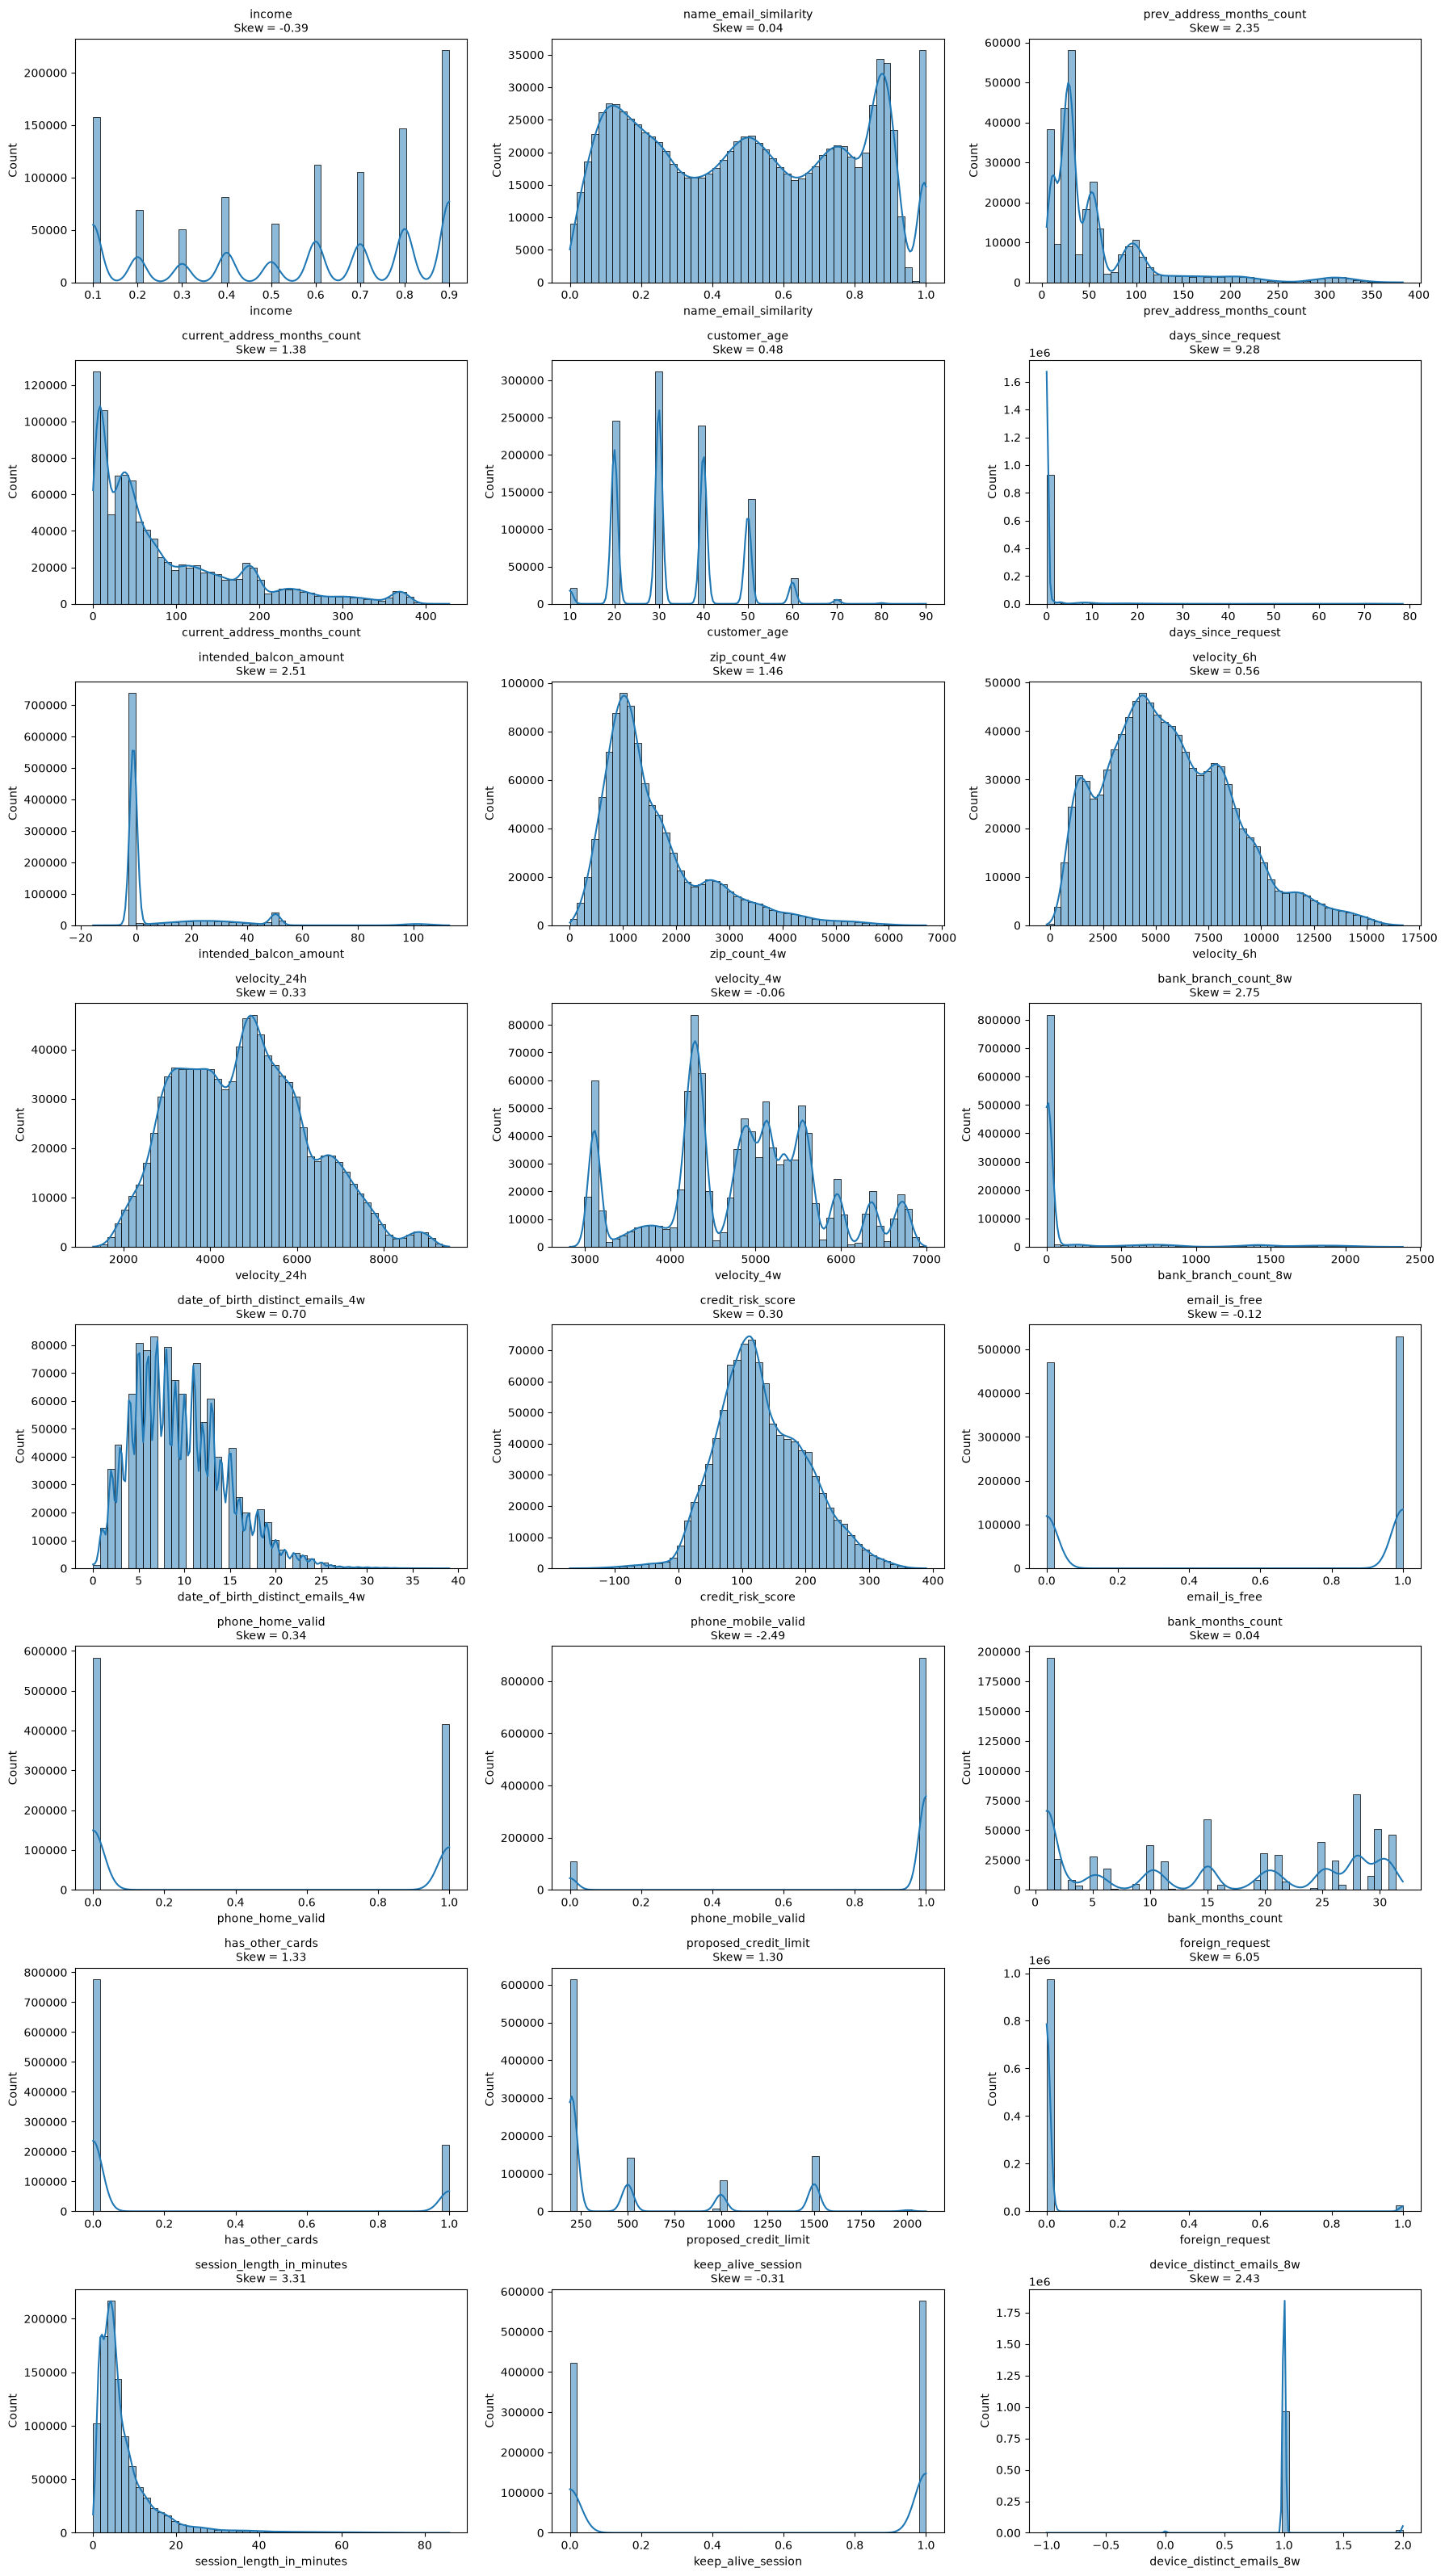

In [8]:
import math
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Variables numéricas (excepto target)
num_cols = [
    c for c in df_data.select_dtypes(include=np.number).columns
    if c != "target"
]

n_cols = 3
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4 * n_rows)
)

axes = axes.flatten()

for ax, col in zip(axes, num_cols):

    sns.histplot(
        df_data[col],
        bins=50,
        kde=True,
        ax=ax
    )

    ax.set_title(
        f"{col}\nSkew = {df_data[col].skew():.2f}",
        fontsize=10
    )

# Eliminar ejes vacíos
for ax in axes[len(num_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

In [9]:
# Variables numéricas
num_cols = df_data.select_dtypes(include=np.number).columns

# Asimetría
skew_table = (
    df_data[num_cols]
    .skew()
    .sort_values(key=np.abs, ascending=False)
    .reset_index()
)

skew_table.columns = ["Variable", "Skewness"]

skew_table

,Variable,Skewness
0,target,9.363838
1,days_since_request,9.278955
2,foreign_request,6.053306
3,session_length_in_minutes,3.308576
4,bank_branch_count_8w,2.747161
5,intended_balcon_amount,2.507173
6,phone_mobile_valid,-2.487616
7,device_distinct_emails_8w,2.430764
8,prev_address_months_count,2.352988
9,zip_count_4w,1.456657


In [10]:
import pandas as pd
import numpy as np

# Variables numéricas
num_cols = df_data.select_dtypes(include=np.number).columns

# Asimetría
skew_table = (
    df_data[num_cols]
    .skew()
    .sort_values(key=np.abs, ascending=False)
    .reset_index()
)

skew_table.columns = ["Variable", "Skewness"]

skew_table

,Variable,Skewness
0,target,9.363838
1,days_since_request,9.278955
2,foreign_request,6.053306
3,session_length_in_minutes,3.308576
4,bank_branch_count_8w,2.747161
5,intended_balcon_amount,2.507173
6,phone_mobile_valid,-2.487616
7,device_distinct_emails_8w,2.430764
8,prev_address_months_count,2.352988
9,zip_count_4w,1.456657


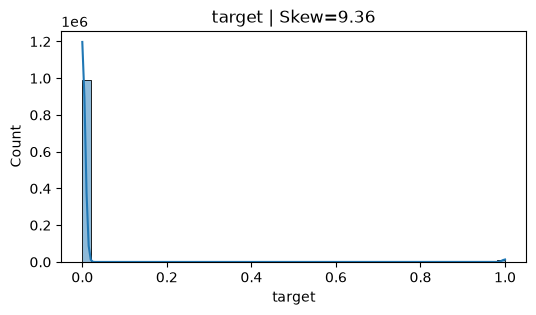

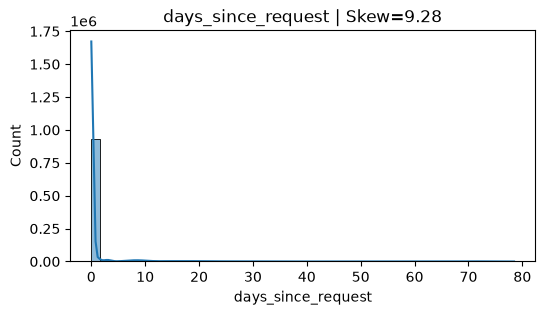

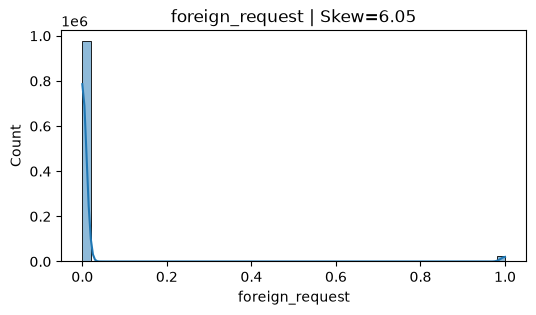

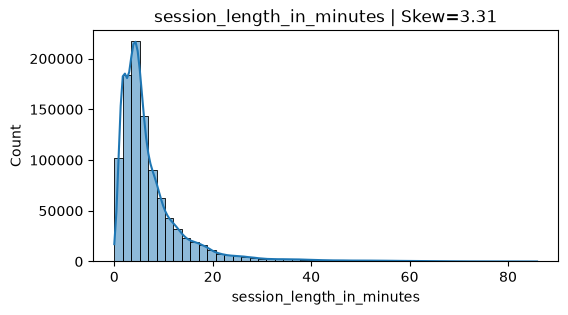

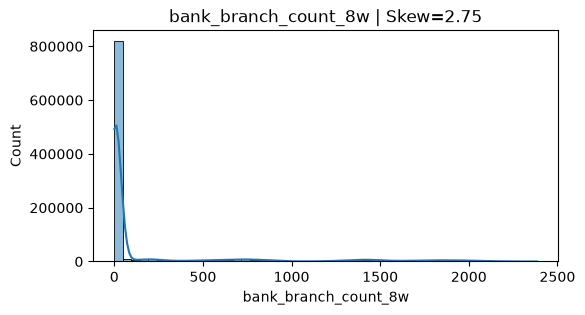

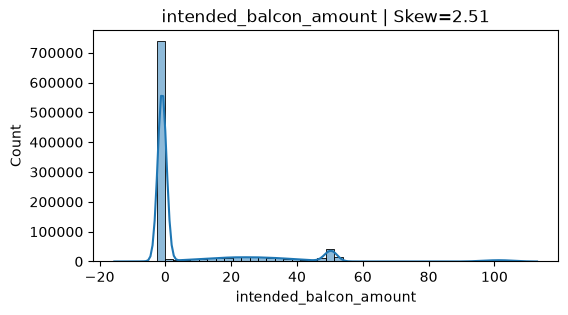

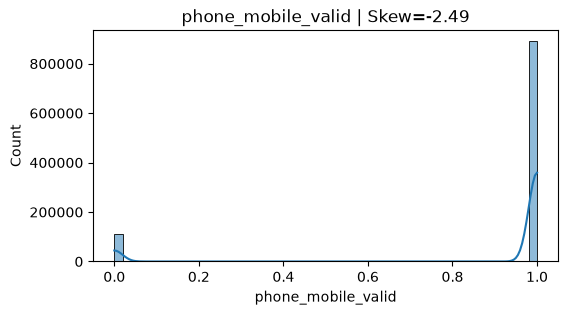

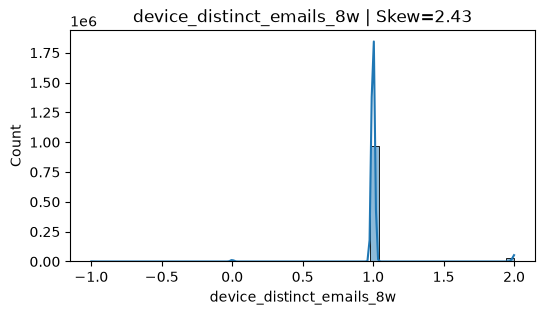

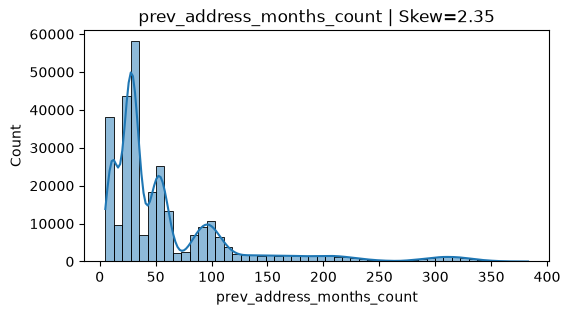

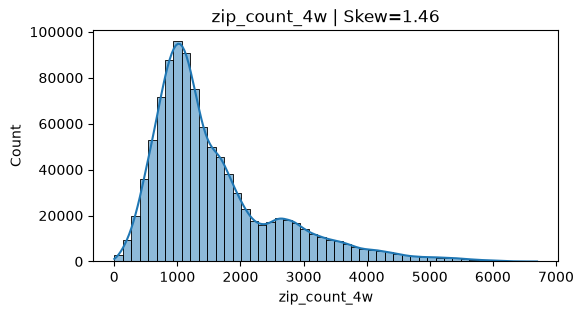

KeyboardInterrupt: 

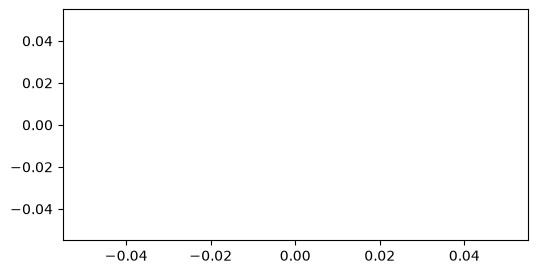

In [11]:
top_skew = (
    skew_table
    .loc[skew_table["Skewness"].abs() > 1, "Variable"]
)

for col in top_skew:

    plt.figure(figsize=(6,3))

    sns.histplot(
        df_data[col],
        bins=50,
        kde=True
    )

    plt.title(f"{col} | Skew={df_data[col].skew():.2f}")

    plt.show()

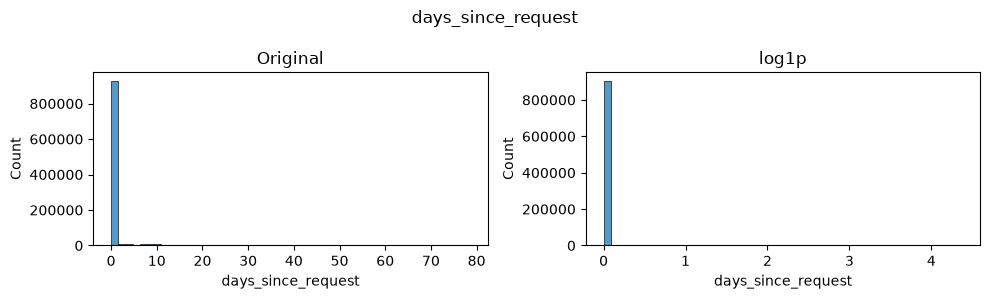

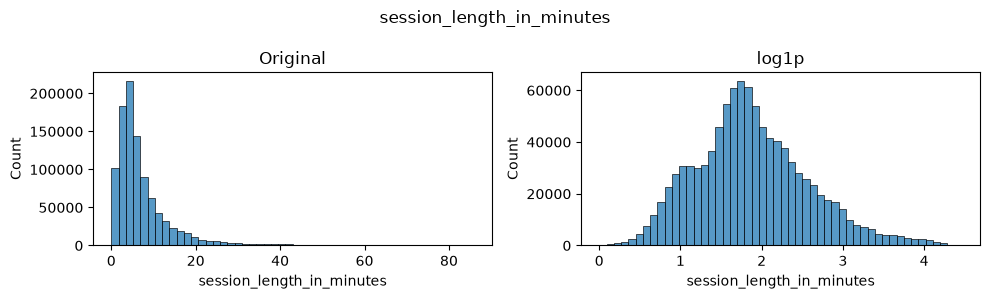

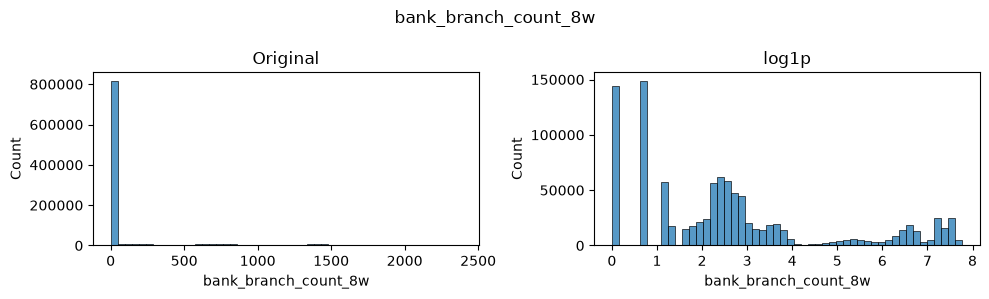

C:\Users\Renzo\AppData\Roaming\Python\Python312\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


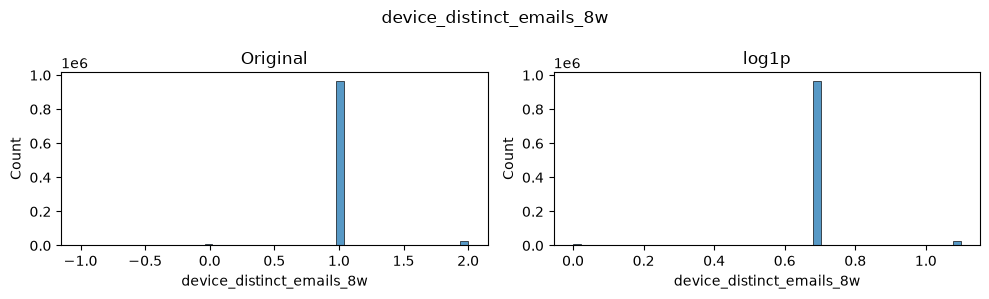

In [ ]:
cols = [
    "days_since_request",
    "session_length_in_minutes",
    "bank_branch_count_8w",
    "device_distinct_emails_8w",
]

for c in cols:

    fig, ax = plt.subplots(1,2, figsize=(10,3))

    sns.histplot(df_data[c], bins=50, ax=ax[0])
    ax[0].set_title("Original")

    sns.histplot(np.log1p(df_data[c]), bins=50, ax=ax[1])
    ax[1].set_title("log1p")

    plt.suptitle(c)

    plt.tight_layout()

    plt.show()

# IV - WoE

In [12]:
from optbinning import OptimalBinning, BinningProcess

In [13]:
def plot_analisis(data, analysis_type, analysis_columns, target, umbral_iv):
    list1 = []
    list2 = []
    tabla_f = pd.DataFrame()
    data[target] = data[target].astype(int)

    # Función para formatear los bins
    def format_bin(bin_value):
        if isinstance(bin_value, tuple):  # Si es un intervalo (tupla)
            return f"[{round(bin_value[0], 4)}, {round(bin_value[1], 4)})"
        elif isinstance(bin_value, (int, float)):  # Si es un número
            return round(bin_value, 4)
        else:  # Si es una cadena (por ejemplo, 'Missing' o 'Special')
            return bin_value

    for columnName in analysis_columns:
        x = data[columnName].values
        y = data[target]
        optb = OptimalBinning(name=columnName, dtype=analysis_type, solver="cp")
        optb.fit(x, y)
        binning_table = optb.binning_table

        tabla = binning_table.build()

        # Formatear los bins a 4 decimales
        if analysis_type == 'numerical':
            tabla['Bin'] = tabla['Bin'].apply(format_bin)

        b = tabla[tabla.index == 'Totals']['IV'][0]
        list1.append(b)
        list2.append(columnName)
        tabla_ = tabla[['Bin', 'WoE']].iloc[:-3]
        tabla_['variable'] = columnName
        tabla_f = pd.concat([tabla_f, tabla_], axis=0)

        print('variable ' + columnName)
        print('---------------------------------------------------------')

        # Imprimir la tabla con 4 decimales
        with pd.option_context('display.float_format', '{:.4f}'.format):
            print(tabla)

        binning_table.plot('event_rate')

    df = pd.DataFrame(pd.Series(list1, index=list2))
    df = df.rename(columns={0: 'IV'})
    df = df[df['IV'] > umbral_iv].sort_values(by='IV', axis=0, ascending=False).reset_index()

    return df

In [14]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [15]:
# ESTO ES PARA DEVOLVER EL WOE PARA LAS CATEGÓRICAS MÁS QUE NADA
def woe_analysis(data, analysis_type, analysis_columns, target):
    list1 = []
    list2 = []
    tabla_f = pd.DataFrame()
    data[target] = data[target].astype(int)
    for columnName in analysis_columns:
        x = data[columnName].values
        y = data[target]
        optb = OptimalBinning(name=columnName, dtype=analysis_type, solver="cp")
        optb.fit(x, y)
        binning_table = optb.binning_table

        tabla = binning_table.build()
        b = tabla[tabla.index == 'Totals']['IV'][0]
        list1.append(b)
        list2.append(columnName)
        tabla_ = tabla[['Bin', 'WoE']].iloc[:-3]
        tabla_['variable'] = columnName
        tabla_f = pd.concat([tabla_f, tabla_], axis=0)
    return tabla_f

In [16]:
# Función para aplicar WoE
def woe_transform(data_cat, columnas_interes, dic_woe):
    """
    Aplica la transformación WoE a un conjunto de datos categóricos.

    Parámetros:
    - data_cat: DataFrame con las variables categóricas.
    - columnas_interes: Lista de columnas categóricas a transformar.
    - dic_woe: Diccionario con los valores de WoE {variable: {categoria: WoE}}.

    Retorna:
    - DataFrame con las variables transformadas a WoE.
    """
    data_cat = data_cat.copy()  # 🔥 Evita modificar el DataFrame original

    for columna in columnas_interes:
        if columna in dic_woe:  # ✅ Verifica si la columna tiene WoE en el diccionario
            data_cat['woe_' + columna] = data_cat[columna].map(dic_woe[columna])
        else:
            print(f"⚠️ Advertencia: No se encontró WoE para la columna '{columna}', se dejará como NaN.")

    columns = ['woe_' + k for k in columnas_interes if 'woe_' + k in data_cat]  # ✅ Solo columnas existentes

    return data_cat[columns]  # ✅ Devuelve solo las columnas transformadas

In [17]:
def selVarWoeIv(data = pd.DataFrame({}), varModel = [], varString = [], exclude = [], target = '', show_plots = 'all', show_variables = 'all',summary_table = True):
    """
    df: dataframe
    varModel: variables del df
    varString: variables del df que son categoricos
    target: columna objetivo
    """
    df = data.copy()
    numRows = df.shape[0]
    numCiclos = range(2,20)
    if (numRows<12):numCiclos = range(2,numRows)
    numTarget = df[target].sum()
    columnNameTarget = target
    efec = numTarget/numRows
    listTransformationWoe = {}
    listIv = {}
    cortes = {}
    varModel = [var for var in varModel if var not in exclude]
    varString = [var for var in varString if var not in exclude]
    error_cols_nn = []
    for columnName in varModel:
        path_changed = False
        print('\n----------------------------')
        print("****\t" + columnName +"\t****")
        print('----------------------------\n')
        listTestIv = []
        tempIv = [0]
        listColumns = []
        iter = 0
        categ = []
        if (columnName not in varString):
            for i in numCiclos:
                percents = [np.round(x / i, 2) for x in range(1, i)]
                listPercent = np.percentile(df[columnName],np.array(percents)*100)
                listPercent = np.round(listPercent,4)
                listPercent = np.insert(listPercent,0,- 999999999999)
                listPercent = np.insert(listPercent, len(listPercent), 999999999999)
                listPercent = np.round(listPercent, 4)
                columnClassPercet = np.zeros(len(df[columnName]))
                columnClassOrden = np.zeros(len(df[columnName]))

                for j in range(len(listPercent)-1):
                    prueba = ((df[columnName] > listPercent[j])&(df[columnName] <= listPercent[j+1])) * listPercent[j+1]
                    columnClassPercet = prueba + columnClassPercet
                    order = ((df[columnName] > listPercent[j])&(df[columnName] <= listPercent[j+1])) * (j+1)
                    columnClassOrden = order + columnClassOrden

                columnClassPercet = np.round(columnClassPercet, 4).astype(str)
                columnClassPercet = np.where(columnClassPercet.str.contains('999999999999'), f'>{listPercent[-2]}', columnClassPercet)
                columnClassOrden = columnClassOrden - 1
                listPercent = listPercent[1:-1]
                listPercent = np.unique(listPercent)

                df['range'] = columnClassPercet
                df['columnClassOrden'] = columnClassOrden
                dfTemp = df.groupby(['range','columnClassOrden'])\
                           .agg(leads = (columnNameTarget, 'count'),
                                target = (columnNameTarget, 'sum'),
                                pctLeads = (columnNameTarget, lambda x: np.round(x.count()/numRows, 4)),
                                efecTarget = (columnNameTarget, lambda x: np.round(x.sum()/x.count(), 4)),
                                pctTarget = (columnNameTarget, lambda x: x.sum()/numTarget),
                                pctNoTarget = (columnNameTarget, lambda x: (x==0).sum()/(numRows - numTarget))
                               ).reset_index()
                numerador = (dfTemp['target'] + 0.5) / numTarget
                denominador = (dfTemp['leads'] - dfTemp['target'] + 0.5)/(numRows - numTarget)
                dfTemp['res2'] = np.log(numerador / denominador)
                dfTemp['res1'] = np.log(dfTemp["pctTarget"]/dfTemp["pctNoTarget"])
                dfTemp['woe'] = np.where(dfTemp["pctTarget"]/dfTemp["pctNoTarget"]<=0, dfTemp['res2'], dfTemp['res1'])
                dfTemp['iv'] = np.where(((dfTemp['pctTarget'] - dfTemp['pctNoTarget'])*dfTemp['woe']).isna(),
                                              0,
                                              (dfTemp['pctTarget'] - dfTemp['pctNoTarget'])*dfTemp['woe'])
                dfTemp.drop(columns = ['res1','res2'], inplace = True)
                dfTemp = dfTemp.sort_values('columnClassOrden')

                iv =  [round(dfTemp[~dfTemp['iv'].isin([np.inf, -np.inf])]['iv'].sum(),4),
                       dfTemp[(dfTemp['columnClassOrden']>=0)&(~dfTemp['iv'].isin([np.inf, -np.inf]))]['pctLeads'].min()]

                if iv[1] >= 0.01:
                    if (iv[0] > np.max(tempIv)):
                        listTestIv.append(iv[0])
                        dfFin = dfTemp.drop(columns = ['columnClassOrden'])
                        ivOpt = iv[0]
                        per = dfFin['range'].tolist()
                        n = dfFin.shape[0]
                        labelIv = 'percentiles'
                        dictDataFrame = dfFin.set_index('range').T.to_dict('list')

                        columnTransform = [[],[]]
                        columnTransform[0] = per
                        for r in per:
                            columnTransform[1].append(np.round(dictDataFrame[r][6],4))

                        categ.append(len(per)+1)
                        tempIv.append(iv[0])
                        iter = iter + 1

            if(iter == 0):
                columnTransform = ""
                ivOpt = 0
                per = []
                labelIv = 'percentiles'
                listTestIv.append(0)
                dfFin = pd.DataFrame([[0,0,0,0,0]], columns=['range','leads','target','efecTarget','woe'])
                n = dfFin.shape[0]
                path_changed = True


        if ((columnName in varString) or (path_changed)):
            if path_changed:
                print('VAR "', columnName, '" CHANGED TO CATEGORICAL')
                data[columnName+'_orig'] = data[columnName].copy()
                if 'varpor' in columnName:
                    data[columnName] = (data[columnName]
                                        .map(lambda x: -999999 if x==-999999.0 else (1 if x>0.0 else (-1 if x<0.0 else 0)))
                                        .astype(str)
                                       )
                else:
                    data[columnName] = (data[columnName]
                                        .map(lambda x: -999999 if x==-999999.0 else (1 if x>0.0 else 0))
                                        .astype(str)
                                       )

                error_cols_nn.append(columnName)
                df = data.copy()

            dfFin = df.groupby(columnName)\
                      .agg(leads = (columnNameTarget, 'count'),
                           target = (columnNameTarget, 'sum'),
                           pctLeads = (columnNameTarget, lambda x: np.round(x.count()/numRows, 4)),
                           efecTarget = (columnNameTarget, lambda x: np.round(x.sum()/x.count(), 4)),
                           pctTarget = (columnNameTarget, lambda x: x.sum()/numTarget),
                           pctNoTarget = (columnNameTarget, lambda x: (x==0).sum()/(numRows - numTarget))
                           ).reset_index()
            dfFin.rename(columns = {columnName:'range'}, inplace = True)
            numerador = (dfFin['target'] + 0.5) / numTarget
            denominador = (dfFin['leads'] - dfFin['target'] + 0.5)/(numRows - numTarget)
            dfFin['res2'] = np.log(numerador / denominador)
            dfFin['res1'] = np.log(dfFin["pctTarget"]/dfFin["pctNoTarget"])
            dfFin['woe'] = np.where(dfFin["pctTarget"]/dfFin["pctNoTarget"]<=0, dfFin['res2'], dfFin['res1'])
            dfFin['iv'] = np.where(((dfFin['pctTarget'] - dfFin['pctNoTarget']) * dfFin['woe']).isna(),
                                          0,
                                          (dfFin['pctTarget'] - dfFin['pctNoTarget']) * dfFin['woe'])
            dfFin.drop(columns = ['res1','res2'], inplace = True)

            iv =  [round(dfFin[~dfFin['iv'].isin([np.inf, -np.inf])]['iv'].sum(),4),
                   dfFin[~dfFin['iv'].isin([np.inf, -np.inf])]['pctLeads'].min()]
            ivOpt=iv[0]
            n = dfFin.shape[0]
            per = [0]
            labelIv = 'categorias'
            categ.append(n)
            listTestIv.append(ivOpt)
            dictDataFrame = dfFin.set_index('range').T.to_dict('list')
            listKeys = list(dictDataFrame.keys())

            columnTransform = [[],[]]
            columnTransform[0] = listKeys
            for j in range(len(listKeys)):
                columnTransform[1].append(dictDataFrame[listKeys[j]][6])

        listTransformationWoe[columnName] = columnTransform
        listIv[columnName] = ivOpt
        pp1 = dfFin[['range','leads','target','efecTarget','woe']]
        listiv = dict(sorted(listIv.items(), key=lambda item: item[1]))
        ejeHor = list(pp1['range'])

        if show_plots == 'all':
            sIv = pd.Series(listTestIv)
            plt.subplot(1,2,1)
            plt.rcParams['figure.figsize'] = (9, 4)
            plt.plot(sIv, marker='*')
            plt.xticks(range(len(categ)),categ)
            plt.title('Gráfico IV')
            plt.xlabel(labelIv)

            plt.subplot(1,2,2)
            pp1['woe'].plot(kind='bar',alpha=0.5, stacked=True, color='k', label='woe')
            plt.xticks(range(len(ejeHor)),ejeHor,rotation=90)
            plt.title('Gráfico WOE')
            plt.xlabel('categorias de variable')

            fig = plt.figure()
            ax = fig.add_subplot(111)
            pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
            pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
            plt.legend(loc = (1.1,0.55), frameon = False)
            plt.xlabel('categorias de variable')
            plt.xticks(range(len(ejeHor)),ejeHor)
            ax2 = ax.twinx()
            xHor = np.arange(len(pp1['range']))
            ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
            ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
            plt.legend( loc = (1.1,0.4), frameon = False)
            fig.autofmt_xdate(rotation=90)
            plt.title(columnName.upper())
            plt.show()

        elif show_plots == 'principal':
            if show_variables == 'principal':
                if ivOpt>0.02:
                    fig = plt.figure()
                    ax = fig.add_subplot(111)
                    pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
                    pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
                    plt.legend(loc = (1.1,0.55), frameon = False)
                    plt.xlabel('categorias de variable')
                    plt.xticks(range(len(ejeHor)),ejeHor)
                    ax2 = ax.twinx()
                    xHor = np.arange(len(pp1['range']))
                    ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
                    ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
                    plt.legend( loc = (1.1,0.4), frameon = False)
                    fig.autofmt_xdate(rotation=90)
                    plt.title(columnName.upper())
                    plt.show()
                else:
                    pass
            else:
                fig = plt.figure()
                ax = fig.add_subplot(111)
                pp1['leads'].plot(kind='bar',alpha=0.5, stacked=True, color='r', label='#leads')
                pp1['target'].plot(kind='bar',alpha=1, stacked=True,color='r', label='#target')
                plt.legend(loc = (1.1,0.55), frameon = False)
                plt.xlabel('categorias de variable')
                plt.xticks(range(len(ejeHor)),ejeHor)
                ax2 = ax.twinx()
                xHor = np.arange(len(pp1['range']))
                ax2.plot(xHor,[efec]*n,linestyle='--', color='k',label='efec. global')
                ax2.plot(xHor,pp1['efecTarget'],linestyle='-', color='b',marker='o',label='efec. target')
                plt.legend( loc = (1.1,0.4), frameon = False)
                fig.autofmt_xdate(rotation=90)
                plt.title(columnName.upper())
                plt.show()
        elif show_plots == 'nothing':
            pass

        if summary_table == True:
            if (columnName not in varString):
                print("\nCon "+str(len(per)+1)+" percentiles: "+ str(per))
                print("Se obtuvo " + str(n) + " categorias")
            else:
                print("\nSe obtuvo " + str(n) + " categorias fijas: ")
            print("iv óptimo: " + str(ivOpt))
            display(dfFin)
            if (len(per) == 0):print('OBSERVACIÓN:\n¡NO SE ENCONTRARON categorías relevantes!\n Podría considerarlo como VARIABLE CATEGÓRICA')
        else:
            pass

        dfFin2 = dfFin[~dfFin['iv'].isin([np.inf, -np.inf])].sort_values(by = 'efecTarget', ascending = False)
        cortes[columnName] = list(dfFin2[dfFin2['efecTarget'] >= efec]['range'])

    plt.figure(figsize = (6,8))
    plt.barh(list(listiv.keys()),list(listiv.values()))
    plt.axvline(0.02, color='red', linestyle = '--') #cambiar linea bsae
    plt.title('Feature Importance')
    plt.show()

    df_importancia = pd.DataFrame(list(listIv.items()), columns = ['variable','iv']).sort_values(by = 'iv', ascending = False).reset_index(drop = True)
    df_cortes = pd.DataFrame(list(cortes.items()), columns = ['variable','corte'])
    df_final = df_importancia.merge(df_cortes, on = 'variable', how = 'left')

    return  df_final, listiv, listTransformationWoe, error_cols_nn


## IV - WoE Numerico

In [18]:
# Seleccionamos numéricas

# Crear un nuevo dataframe con solo las columnas numéricas
df_numeric = df_data.select_dtypes(include=[int, float])

# Obtener la lista de columnas
columnas_numericas = df_numeric.columns.tolist()

In [19]:
import sklearn, optbinning
print("sklearn:", sklearn.__version__)
print("optbinning:", optbinning.__version__)

sklearn: 1.6.0
optbinning: 0.21.0


variable target
---------------------------------------------------------
                Bin    Count  Count (%)  Non-event  Event  Event rate    WoE  \
0       (-inf, inf)  1000000     1.0000     988971  11029      0.0110 0.0000   
1           Special        0     0.0000          0      0      0.0000 0.0000   
2           Missing        0     0.0000          0      0      0.0000 0.0000   
Totals               1000000     1.0000     988971  11029      0.0110          

           IV     JS  
0      0.0000 0.0000  
1      0.0000 0.0000  
2      0.0000 0.0000  
Totals 0.0000 0.0000  


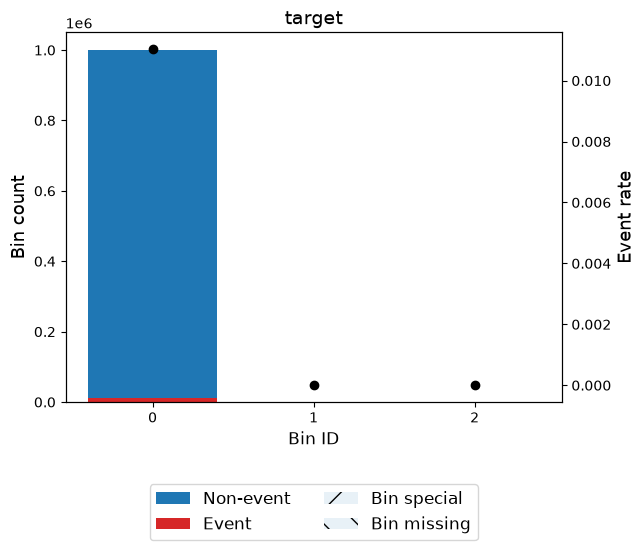

variable income
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.15)   157449     0.1574     156540    909      0.0058   
1       [0.15, 0.25)    69345     0.0693      68907    438      0.0063   
2       [0.25, 0.35)    50833     0.0508      50495    338      0.0066   
3       [0.35, 0.45)    81364     0.0814      80767    597      0.0073   
4       [0.45, 0.55)    55858     0.0559      55414    444      0.0079   
5       [0.55, 0.65)   111973     0.1120     110990    983      0.0088   
6       [0.65, 0.75)   105109     0.1051     104182    927      0.0088   
7       [0.75, 0.85)   146650     0.1467     145048   1602      0.0109   
8        [0.85, inf)   221419     0.2214     216628   4791      0.0216   
9            Special        0     0.0000          0      0      0.0000   
10           Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.00

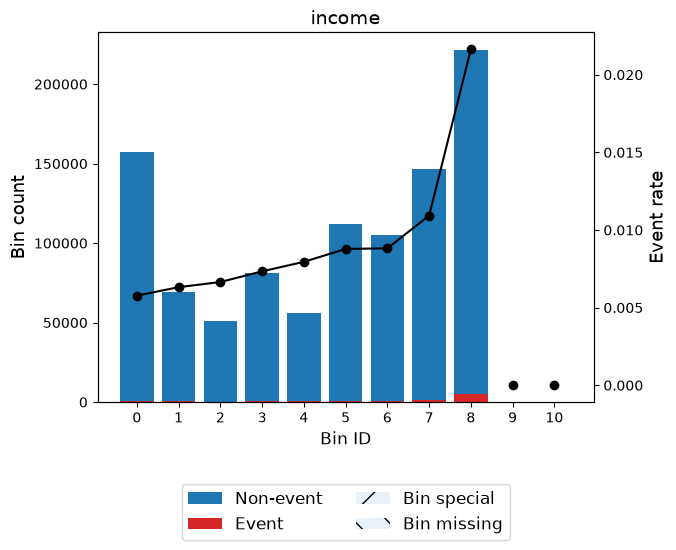

variable name_email_similarity
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.10)    90061     0.0901      88191   1870      0.0208   
1       [0.10, 0.17)    97970     0.0980      96104   1866      0.0190   
2       [0.17, 0.25)    88780     0.0888      87504   1276      0.0144   
3       [0.25, 0.35)    90460     0.0905      89410   1050      0.0116   
4       [0.35, 0.46)    92637     0.0926      91890    747      0.0081   
5       [0.46, 0.51)    56000     0.0560      55652    348      0.0062   
6       [0.51, 0.67)   149386     0.1494     148338   1048      0.0070   
7        [0.67, inf)   334706     0.3347     331882   2824      0.0084   
8            Special        0     0.0000          0      0      0.0000   
9            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV 

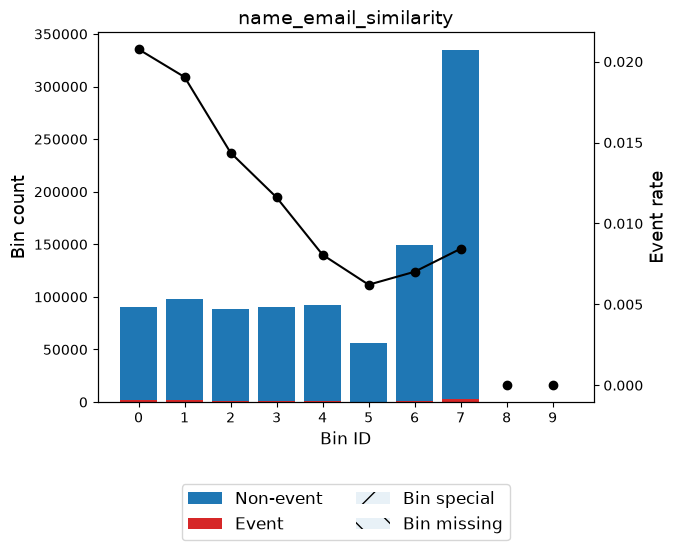

variable prev_address_months_count
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 26.50)    81440     0.0814      81260    180      0.0022   
1       [26.50, 90.50)   145963     0.1460     145568    395      0.0027   
2         [90.50, inf)    59677     0.0597      59357    320      0.0054   
3              Special        0     0.0000          0      0      0.0000   
4              Missing   712920     0.7129     702786  10134      0.0142   
Totals                  1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0       1.6163 0.1064 0.0120  
1       1.4134 0.1574 0.0182  
2       0.7269 0.0225 0.0028  
3       0.0000 0.0000 0.0000  
4      -0.2570 0.0535 0.0067  
Totals         0.3399 0.0396  


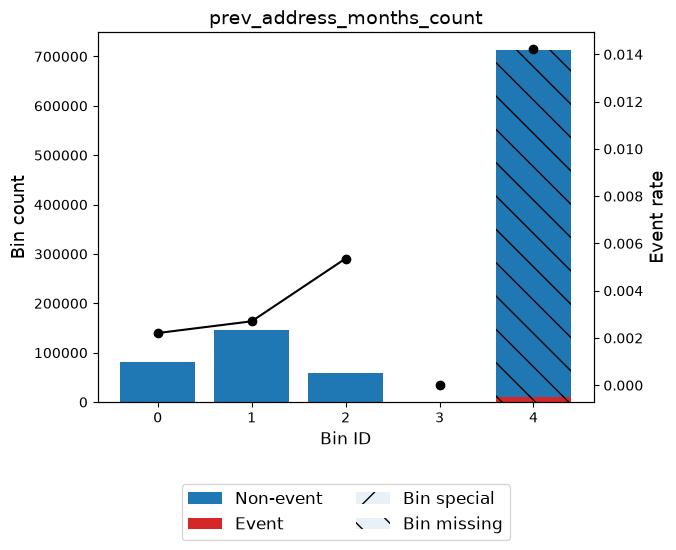

variable current_address_months_count
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 6.50)    94935     0.0949      94586    349      0.0037   
1        [6.50, 11.50)    76774     0.0768      76539    235      0.0031   
2       [11.50, 17.50)    61759     0.0618      61545    214      0.0035   
3       [17.50, 31.50)    93305     0.0933      92853    452      0.0048   
4       [31.50, 38.50)    61456     0.0615      61068    388      0.0063   
5       [38.50, 46.50)    67875     0.0679      67314    561      0.0083   
6       [46.50, 54.50)    53538     0.0535      52846    692      0.0129   
7       [54.50, 65.50)    54477     0.0545      53605    872      0.0160   
8         [65.50, inf)   431627     0.4316     424375   7252      0.0168   
9              Special        0     0.0000          0      0      0.0000   
10             Missing     4254     0.0043       4240     14      0.

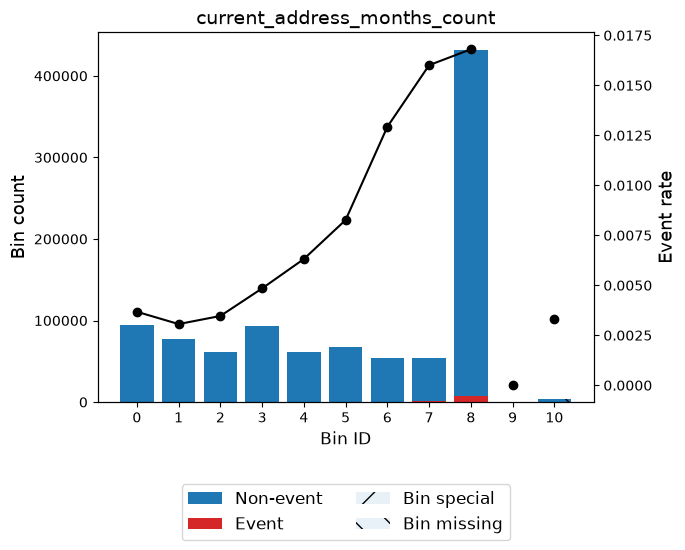

variable customer_age
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 25.00)   266842     0.2668     265563   1279      0.0048   
1       [25.00, 35.00)   311433     0.3114     308844   2589      0.0083   
2       [35.00, 45.00)   238712     0.2387     235836   2876      0.0120   
3         [45.00, inf)   183013     0.1830     178728   4285      0.0234   
4              Special        0     0.0000          0      0      0.0000   
5              Missing        0     0.0000          0      0      0.0000   
Totals                  1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0       0.8396 0.1281 0.0156  
1       0.2854 0.0221 0.0028  
2      -0.0894 0.0020 0.0002  
3      -0.7654 0.1590 0.0194  
4       0.0000 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
Totals         0.3113 0.0380  


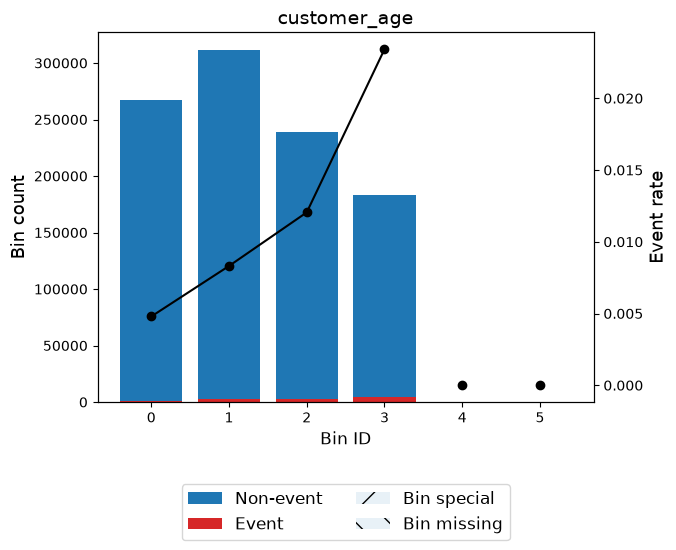

variable days_since_request
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.00)    55024     0.0550      54244    780      0.0142   
1       [0.00, 0.01)   173674     0.1737     171388   2286      0.0132   
2       [0.01, 0.01)   120386     0.1204     118951   1435      0.0119   
3       [0.01, 0.02)   204983     0.2050     202618   2365      0.0115   
4       [0.02, 0.02)    88211     0.0882      87300    911      0.0103   
5       [0.02, 0.02)    52997     0.0530      52492    505      0.0095   
6       [0.02, 0.03)   113078     0.1131     112125    953      0.0084   
7       [0.03, 0.37)    99066     0.0991      98493    573      0.0058   
8        [0.37, inf)    92581     0.0926      91360   1221      0.0132   
9            Special        0     0.0000          0      0      0.0000   
10           Missing        0     0.0000          0      0      0.0000   
Totals                1000

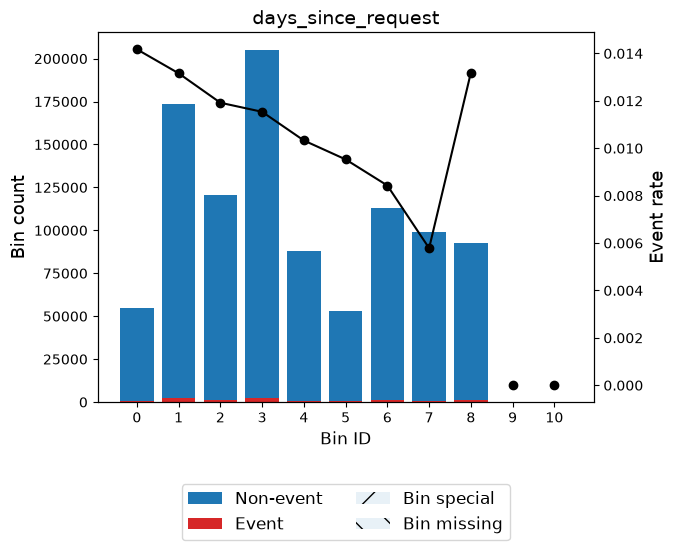

variable intended_balcon_amount
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 0.07)   743314     0.7433     733549   9765      0.0131   
1        [0.07, 19.69)    59794     0.0598      59558    236      0.0039   
2       [19.69, 50.39)   146892     0.1469     146182    710      0.0048   
3         [50.39, inf)    50000     0.0500      49682    318      0.0064   
4              Special        0     0.0000          0      0      0.0000   
5              Missing        0     0.0000          0      0      0.0000   
Totals                  1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.1770 0.0254 0.0032  
1       1.0347 0.0402 0.0048  
2       0.8312 0.0694 0.0084  
3       0.5552 0.0119 0.0015  
4       0.0000 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
Totals         0.1468 0.0179  


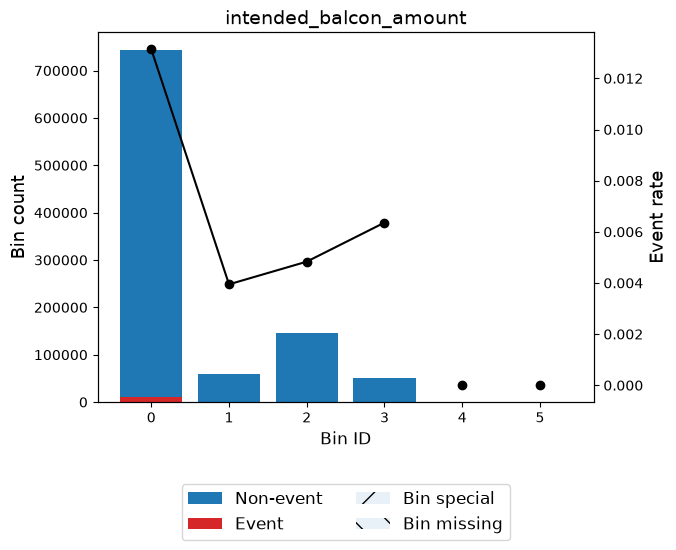

variable zip_count_4w
---------------------------------------------------------
                       Bin    Count  Count (%)  Non-event  Event  Event rate  \
0           (-inf, 942.50)   283097     0.2831     280075   3022      0.0107   
1        [942.50, 1045.50)    73796     0.0738      73058    738      0.0100   
2       [1045.50, 1124.50)    55520     0.0555      55015    505      0.0091   
3       [1124.50, 1275.50)    94952     0.0950      94003    949      0.0100   
4       [1275.50, 1513.50)   108148     0.1081     106973   1175      0.0109   
5       [1513.50, 1871.50)   117119     0.1171     115759   1360      0.0116   
6           [1871.50, inf)   267368     0.2674     264088   3280      0.0123   
7                  Special        0     0.0000          0      0      0.0000   
8                  Missing        0     0.0000          0      0      0.0000   
Totals                      1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0       

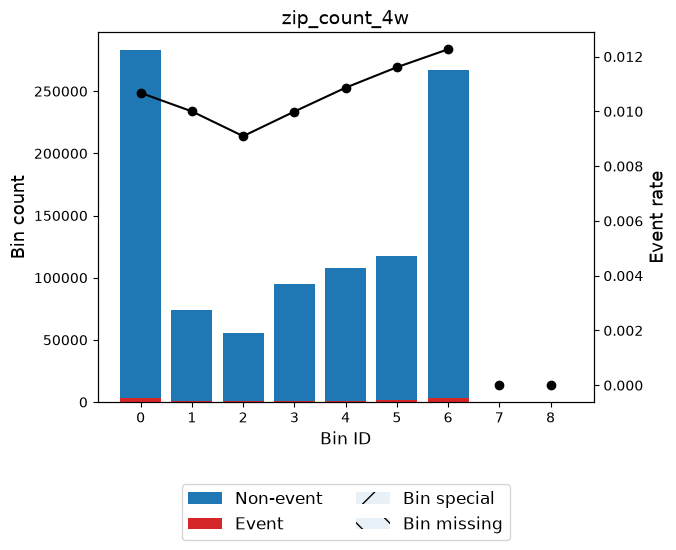

variable velocity_6h
---------------------------------------------------------
                       Bin    Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 1312.93)    53596     0.0536      52760    836      0.0156   
1       [1312.93, 2679.78)   115123     0.1151     113430   1693      0.0147   
2       [2679.78, 5778.84)   387772     0.3878     383474   4298      0.0111   
3       [5778.84, 7493.96)   175574     0.1756     173763   1811      0.0103   
4       [7493.96, 8105.80)    60009     0.0600      59403    606      0.0101   
5       [8105.80, 9696.26)   110839     0.1108     109750   1089      0.0098   
6           [9696.26, inf)    97087     0.0971      96391    696      0.0072   
7                  Special        0     0.0000          0      0      0.0000   
8                  Missing        0     0.0000          0      0      0.0000   
Totals                      1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0

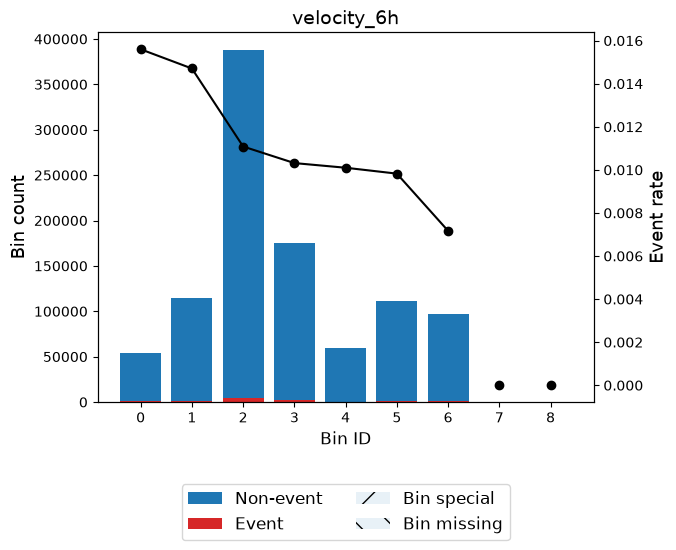

variable velocity_24h
---------------------------------------------------------
                       Bin    Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 3064.48)   133781     0.1338     131857   1924      0.0144   
1       [3064.48, 3383.27)    70158     0.0702      69332    826      0.0118   
2       [3383.27, 5141.45)   406552     0.4066     402063   4489      0.0110   
3       [5141.45, 5959.54)   180962     0.1810     179017   1945      0.0107   
4       [5959.54, 6490.21)    71365     0.0714      70649    716      0.0100   
5       [6490.21, 7113.55)    67590     0.0676      67055    535      0.0079   
6           [7113.55, inf)    69592     0.0696      68998    594      0.0085   
7                  Special        0     0.0000          0      0      0.0000   
8                  Missing        0     0.0000          0      0      0.0000   
Totals                      1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -

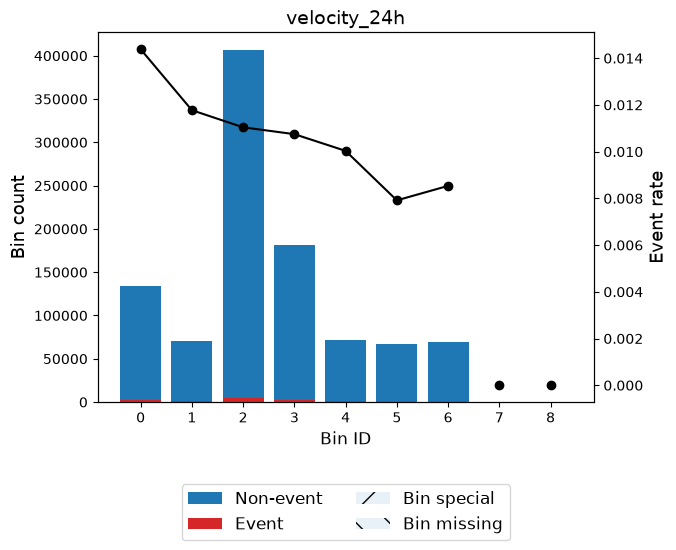

variable velocity_4w
---------------------------------------------------------
                       Bin    Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 4081.97)   149179     0.1492     146954   2225      0.0149   
1       [4081.97, 4212.06)    50553     0.0506      49821    732      0.0145   
2       [4212.06, 4271.37)    53224     0.0532      52632    592      0.0111   
3       [4271.37, 5043.04)   305257     0.3053     301932   3325      0.0109   
4       [5043.04, 5582.10)   248568     0.2486     246347   2221      0.0089   
5       [5582.10, 5853.65)    57892     0.0579      57506    386      0.0067   
6       [5853.65, 6457.01)    85227     0.0852      84340    887      0.0104   
7           [6457.01, inf)    50100     0.0501      49439    661      0.0132   
8                  Special        0     0.0000          0      0      0.0000   
9                  Missing        0     0.0000          0      0      0.0000   
Totals                      1000000     1

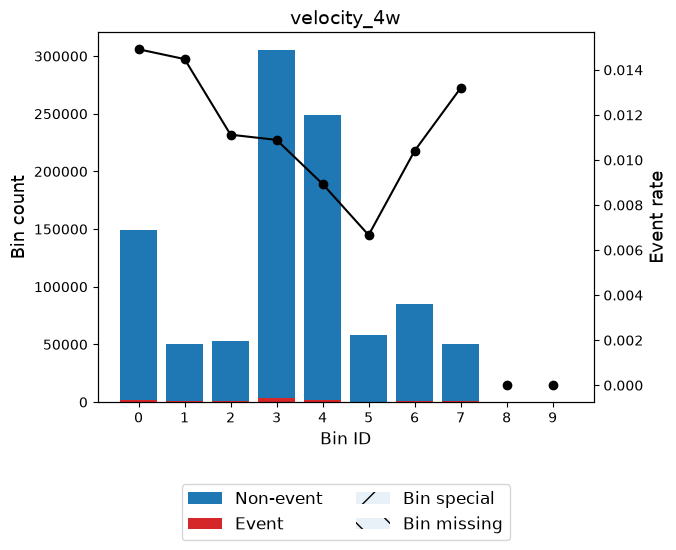

variable bank_branch_count_8w
---------------------------------------------------------
                      Bin    Count  Count (%)  Non-event  Event  Event rate  \
0            (-inf, 0.50)   144376     0.1444     141811   2565      0.0178   
1            [0.50, 1.50)   149028     0.1490     146633   2395      0.0161   
2            [1.50, 2.50)    57792     0.0578      57063    729      0.0126   
3           [2.50, 16.50)   338035     0.3380     335077   2958      0.0088   
4         [16.50, 312.50)   167108     0.1671     165731   1377      0.0082   
5       [312.50, 1397.50)    84646     0.0846      84193    453      0.0054   
6          [1397.50, inf)    59015     0.0590      58463    552      0.0094   
7                 Special        0     0.0000          0      0      0.0000   
8                 Missing        0     0.0000          0      0      0.0000   
Totals                     1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.4

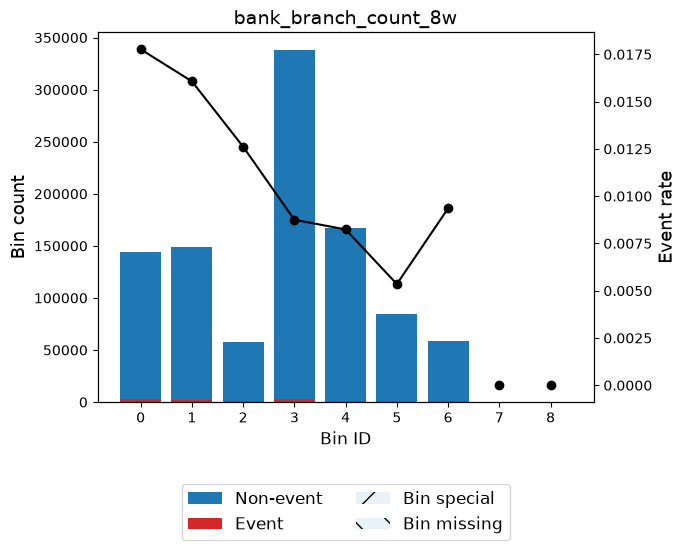

variable date_of_birth_distinct_emails_4w
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 2.50)    51430     0.0514      49606   1824      0.0355   
1         [2.50, 4.50)   106776     0.1068     105164   1612      0.0151   
2         [4.50, 8.50)   321708     0.3217     317927   3781      0.0118   
3         [8.50, 9.50)    67341     0.0673      66585    756      0.0112   
4        [9.50, 10.50)    62681     0.0627      62135    546      0.0087   
5       [10.50, 12.50)   125865     0.1259     124995    870      0.0069   
6       [12.50, 13.50)    60773     0.0608      60384    389      0.0064   
7         [13.50, inf)   203426     0.2034     202175   1251      0.0061   
8              Special        0     0.0000          0      0      0.0000   
9              Missing        0     0.0000          0      0      0.0000   
Totals                  1000000     1.0000     988971  11029    

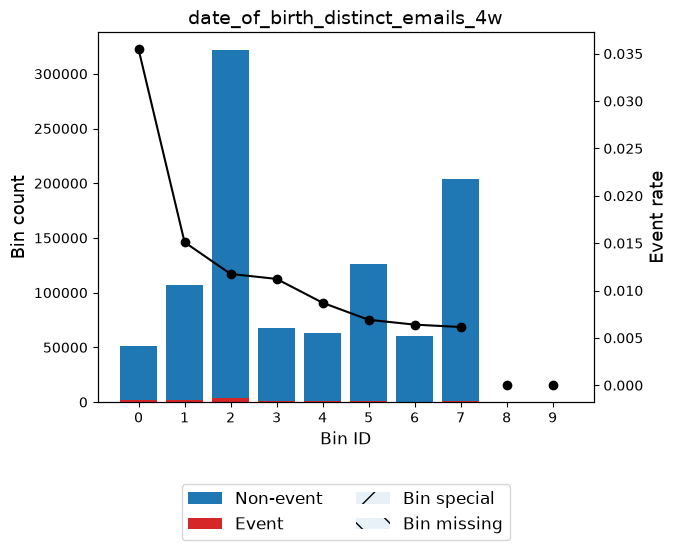

variable credit_risk_score
---------------------------------------------------------
                     Bin    Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 45.50)    92595     0.0926      92117    478      0.0052   
1        [45.50, 127.50)   438424     0.4384     435536   2888      0.0066   
2       [127.50, 137.50)    54379     0.0544      54009    370      0.0068   
3       [137.50, 157.50)    86374     0.0864      85578    796      0.0092   
4       [157.50, 173.50)    61281     0.0613      60537    744      0.0121   
5       [173.50, 198.50)    89811     0.0898      88659   1152      0.0128   
6       [198.50, 219.50)    62012     0.0620      61044    968      0.0156   
7       [219.50, 250.50)    58755     0.0588      57529   1226      0.0209   
8          [250.50, inf)    56369     0.0564      53962   2407      0.0427   
9                Special        0     0.0000          0      0      0.0000   
10               Missing        0     0.0000          0  

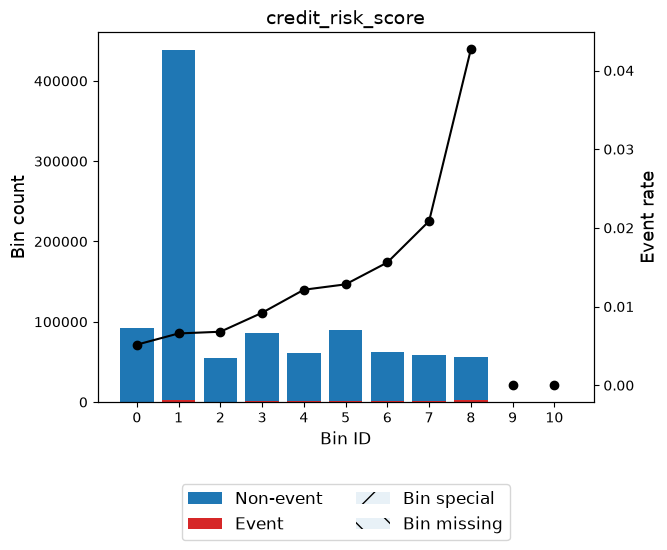

variable email_is_free
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   470114     0.4701     466376   3738      0.0080   
1        [0.50, inf)   529886     0.5299     522595   7291      0.0138   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0       0.3303 0.0438 0.0055  
1      -0.2240 0.0297 0.0037  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.0735 0.0092  


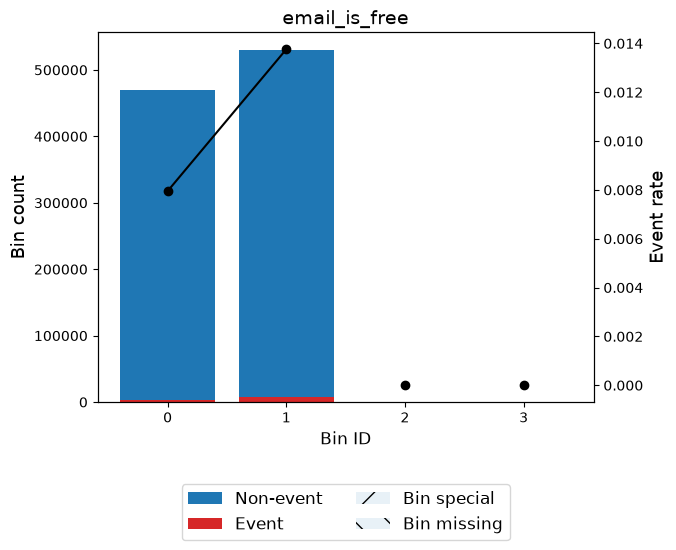

variable phone_home_valid
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   582923     0.5829     574685   8238      0.0141   
1        [0.50, inf)   417077     0.4171     414286   2791      0.0067   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.2511 0.0416 0.0052  
1       0.5040 0.0836 0.0103  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.1252 0.0155  


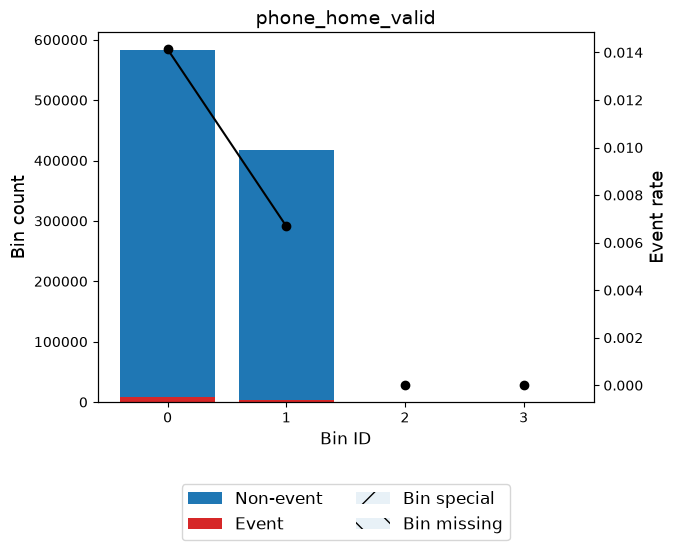

variable phone_mobile_valid
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   110324     0.1103     108676   1648      0.0149   
1        [0.50, inf)   889676     0.8897     880295   9381      0.0105   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.3073 0.0122 0.0015  
1       0.0454 0.0018 0.0002  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.0139 0.0017  


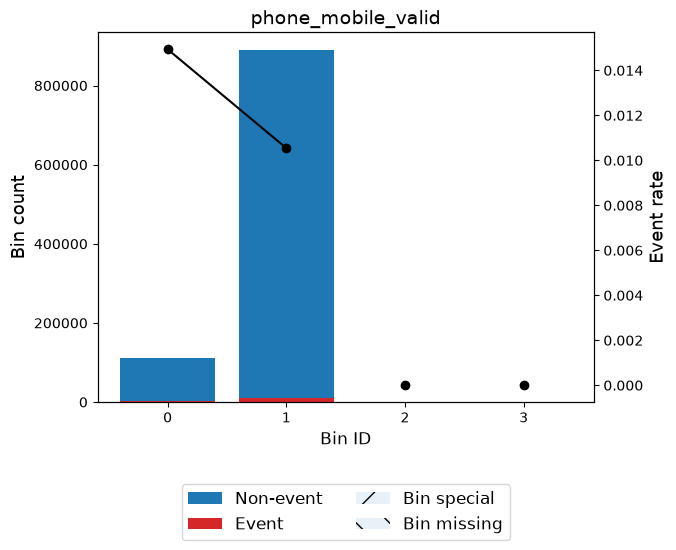

variable bank_months_count
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 1.50)   194802     0.1948     193530   1272      0.0065   
1        [1.50, 23.50)   291630     0.2916     289248   2382      0.0082   
2       [23.50, 29.50)   163026     0.1630     161402   1624      0.0100   
3         [29.50, inf)    96907     0.0969      95296   1611      0.0166   
4              Special        0     0.0000          0      0      0.0000   
5              Missing   253635     0.2536     249495   4140      0.0163   
Totals                  1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0       0.5287 0.0425 0.0052  
1       0.3032 0.0232 0.0029  
2       0.1029 0.0016 0.0002  
3      -0.4160 0.0207 0.0026  
4       0.0000 0.0000 0.0000  
5      -0.3974 0.0489 0.0061  
Totals         0.1369 0.0170  


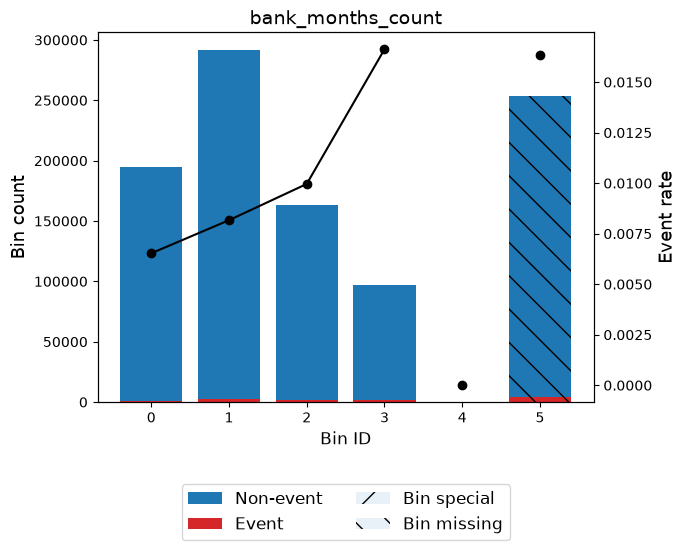

variable has_other_cards
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   777012     0.7770     766914  10098      0.0130   
1        [0.50, inf)   222988     0.2230     222057    931      0.0042   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.1661 0.0233 0.0029  
1       0.9783 0.1371 0.0165  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.1604 0.0194  


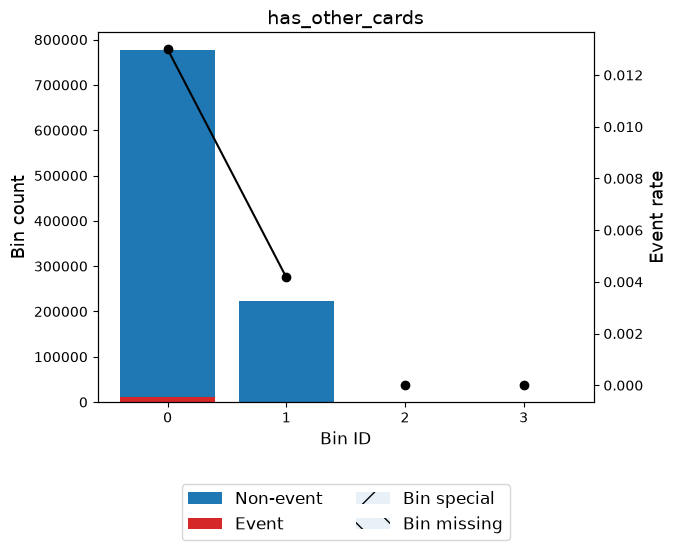

variable proposed_credit_limit
---------------------------------------------------------
                      Bin    Count  Count (%)  Non-event  Event  Event rate  \
0          (-inf, 350.00)   614624     0.6146     610198   4426      0.0072   
1        [350.00, 750.00)   143634     0.1436     142132   1502      0.0105   
2       [750.00, 1250.00)    89462     0.0895      88422   1040      0.0116   
3          [1250.00, inf)   152280     0.1523     148219   4061      0.0267   
4                 Special        0     0.0000          0      0      0.0000   
5                 Missing        0     0.0000          0      0      0.0000   
Totals                     1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0       0.4302 0.0928 0.0115  
1       0.0538 0.0004 0.0001  
2      -0.0532 0.0003 0.0000  
3      -0.8989 0.1963 0.0237  
4       0.0000 0.0000 0.0000  
5       0.0000 0.0000 0.0000  
Totals         0.2897 0.0353  


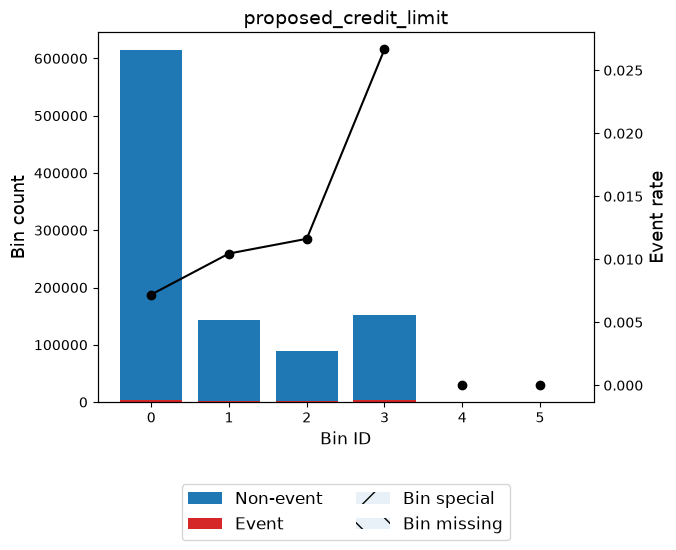

variable foreign_request
---------------------------------------------------------
                Bin    Count  Count (%)  Non-event  Event  Event rate    WoE  \
0       (-inf, inf)  1000000     1.0000     988971  11029      0.0110 0.0000   
1           Special        0     0.0000          0      0      0.0000 0.0000   
2           Missing        0     0.0000          0      0      0.0000 0.0000   
Totals               1000000     1.0000     988971  11029      0.0110          

           IV     JS  
0      0.0000 0.0000  
1      0.0000 0.0000  
2      0.0000 0.0000  
Totals 0.0000 0.0000  


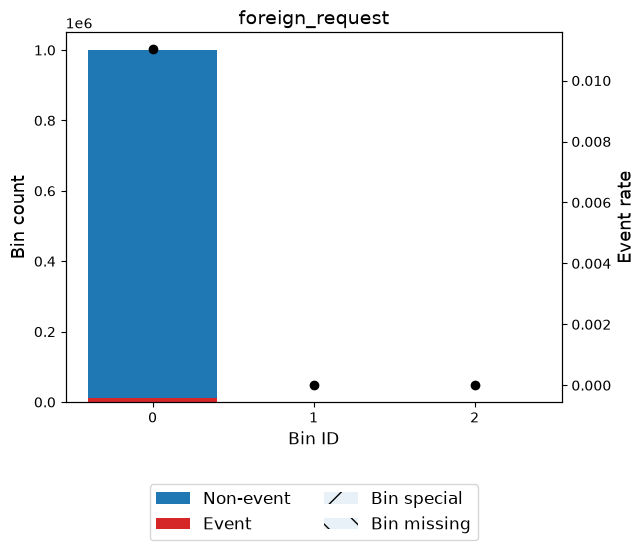

variable session_length_in_minutes
---------------------------------------------------------
                   Bin    Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 8.02)   708409     0.7084     700461   7948      0.0112   
1         [8.02, 9.61)    67905     0.0679      67177    728      0.0107   
2        [9.61, 11.64)    55634     0.0556      55122    512      0.0092   
3       [11.64, 15.27)    62262     0.0623      61788    474      0.0076   
4       [15.27, 21.58)    53243     0.0532      52731    512      0.0096   
5         [21.58, inf)    50532     0.0505      49695    837      0.0166   
6              Special        0     0.0000          0      0      0.0000   
7              Missing     2015     0.0020       1997     18      0.0089   
Totals                  1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.0173 0.0002 0.0000  
1       0.0286 0.0001 0.0000  
2       0.1828 0.0017 0.0002  
3       0.3741 0.0073 

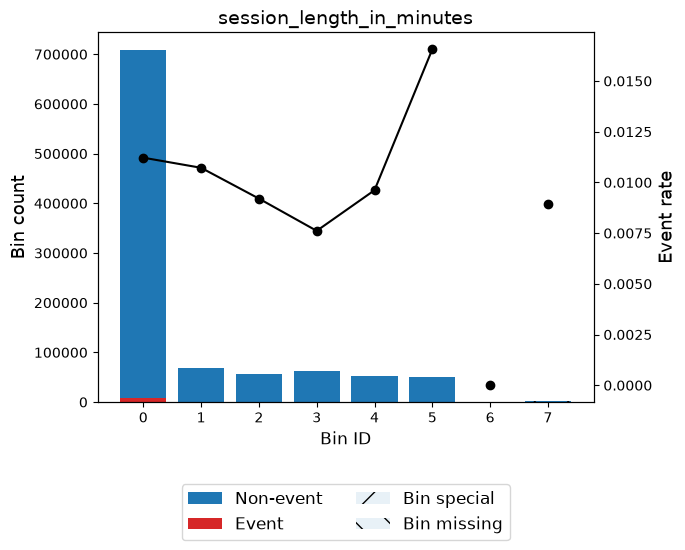

variable keep_alive_session
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   423053     0.4231     415792   7261      0.0172   
1        [0.50, inf)   576947     0.5769     573179   3768      0.0065   
2            Special        0     0.0000          0      0      0.0000   
3            Missing        0     0.0000          0      0      0.0000   
Totals                1000000     1.0000     988971  11029      0.0110   

           WoE     IV     JS  
0      -0.4485 0.1067 0.0132  
1       0.5285 0.1257 0.0155  
2       0.0000 0.0000 0.0000  
3       0.0000 0.0000 0.0000  
Totals         0.2325 0.0288  


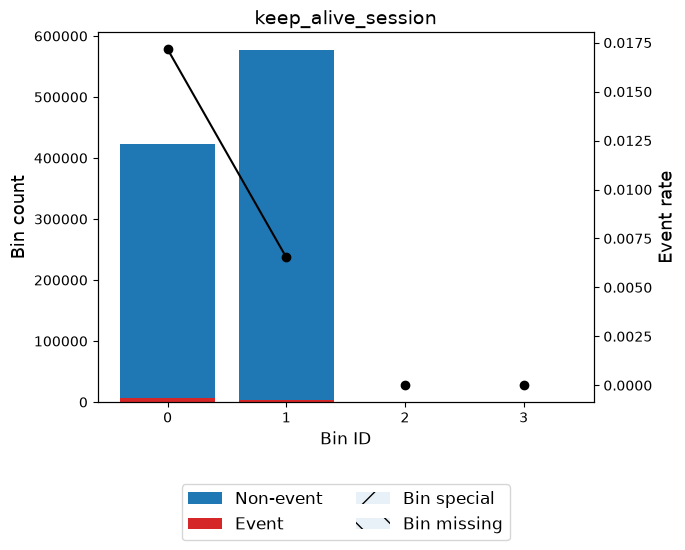

variable device_distinct_emails_8w
---------------------------------------------------------
                Bin    Count  Count (%)  Non-event  Event  Event rate    WoE  \
0       (-inf, inf)  1000000     1.0000     988971  11029      0.0110 0.0000   
1           Special        0     0.0000          0      0      0.0000 0.0000   
2           Missing        0     0.0000          0      0      0.0000 0.0000   
Totals               1000000     1.0000     988971  11029      0.0110          

           IV     JS  
0      0.0000 0.0000  
1      0.0000 0.0000  
2      0.0000 0.0000  
Totals 0.0000 0.0000  


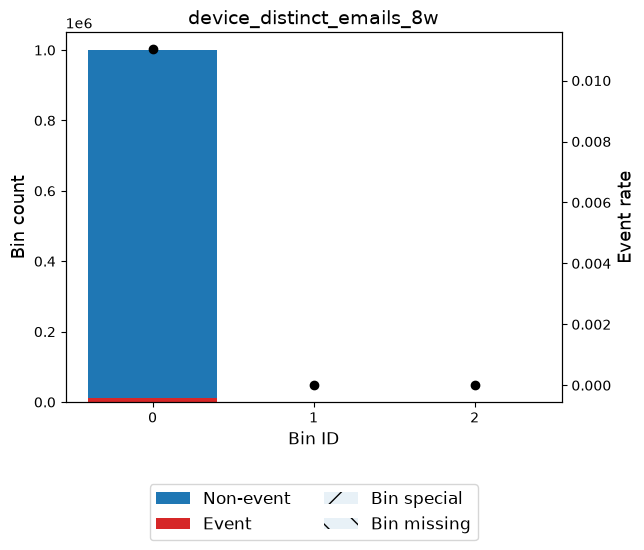

In [22]:
df_result = plot_analisis(df_numeric, 'numerical', columnas_numericas, 'target', 0.09)

In [23]:
# Configurar Pandas para una mejor visualización
pd.set_option('display.max_rows', None)  # Mostrar todas las filas
pd.set_option('display.max_columns', None)  # Mostrar todas las columnas
pd.set_option('display.width', 1000)  # Ajustar el ancho de la visualización
pd.set_option('display.max_colwidth', 50)  # Limitar el ancho de las celdas

In [24]:
# Ver el DataFrame completo
print(df_result)

                               index        IV
0                  credit_risk_score  0.417043
1       current_address_months_count  0.368898
2          prev_address_months_count  0.339891
3                       customer_age  0.311268
4              proposed_credit_limit  0.289707
5                             income  0.250911
6   date_of_birth_distinct_emails_4w  0.244854
7                 keep_alive_session  0.232451
8              name_email_similarity  0.167995
9                    has_other_cards  0.160352
10            intended_balcon_amount  0.146844
11                 bank_months_count  0.136918
12              bank_branch_count_8w  0.133252
13                  phone_home_valid  0.125229


## IV - Woe Categorico

In [25]:
# Seleccionamos categóricas

# Crear un nuevo dataframe con solo las columnas categóricas
df_categoricals = df_data.select_dtypes(include=['object', 'category'])

# Obtener la lista de columnas categóricas
columnas_categoricas = df_categoricals.columns.tolist()

# Agregar la variable target al DataFrame df_categoricals
df_categoricals['target'] = df_data['target']

# Columnas a excluir
columnas_a_excluir = []
#'periodo',id_cliente_persona', 'id_resppago', 'tip_documento'

# Excluir las columnas no deseadas del DataFrame df_categoricals
df_cat = df_categoricals.drop(columns=columnas_a_excluir)

# Actualizar la lista de columnas categóricas para excluir las columnas no deseadas
columnas_categoricas = [col for col in columnas_categoricas if col not in columnas_a_excluir]

# Verificar el resultado
print("Columnas en df_cat después de excluir las no deseadas:")
print(df_cat.columns.tolist())

Columnas en df_cat después de excluir las no deseadas:
['payment_type', 'employment_status', 'housing_status', 'source', 'device_os', 'period', 'target']


variable payment_type
---------------------------------------------------------
             Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       [AE, AA]   258538     0.2585     257173   1365      0.0053  0.7425 0.1012 0.0124
1           [AD]   118837     0.1188     117551   1286      0.0108  0.0192 0.0000 0.0000
2           [AB]   370554     0.3706     366385   4169      0.0113 -0.0201 0.0002 0.0000
3           [AC]   252071     0.2521     247862   4209      0.0167 -0.4205 0.0551 0.0068
4        Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
5        Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals            1000000     1.0000     988971  11029      0.0110         0.1565 0.0192


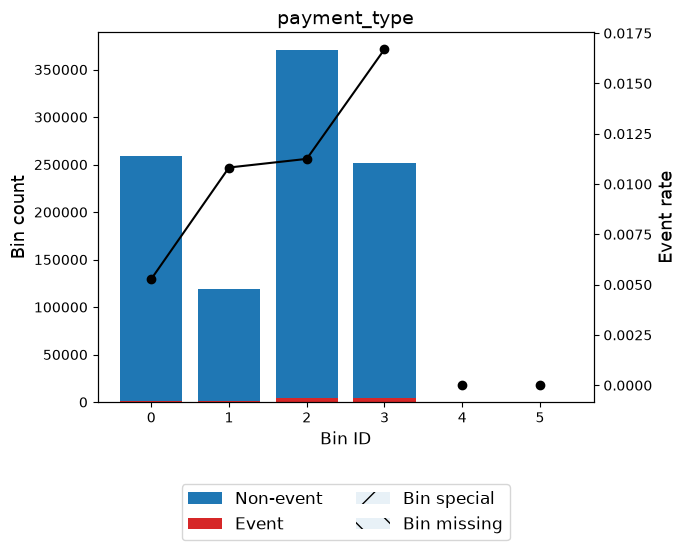

variable employment_status
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       [CF, CE, CD]    93249     0.0932      93011    238      0.0026  1.4721 0.1067 0.0122
1               [CB]   138288     0.1383     137335    953      0.0069  0.4744 0.0249 0.0031
2       [CA, CG, CC]   768463     0.7685     758625   9838      0.0128 -0.1509 0.0188 0.0024
3            Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
4            Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals                1000000     1.0000     988971  11029      0.0110         0.1504 0.0177


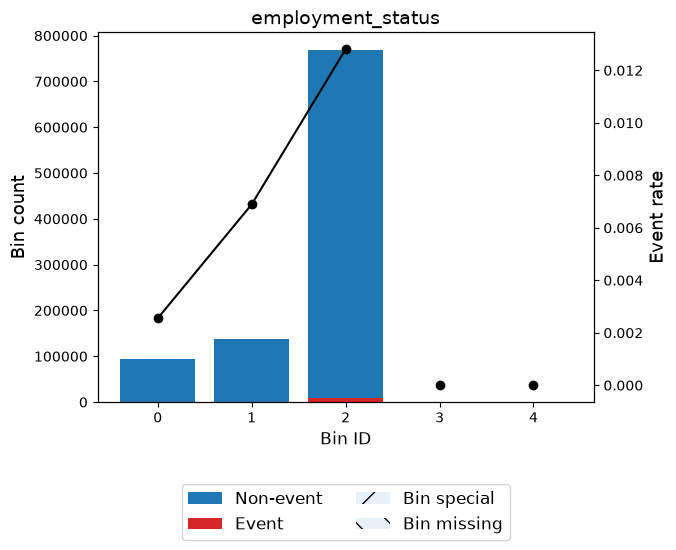

variable housing_status
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       [BE, BG, BF]   171056     0.1711     170466    590      0.0034  1.1700 0.1391 0.0165
1               [BB]   260965     0.2610     259397   1568      0.0060  0.6124 0.0736 0.0091
2           [BC, BD]   398304     0.3983     395790   2514      0.0063  0.5629 0.0970 0.0120
3               [BA]   169675     0.1697     163318   6357      0.0375 -1.2500 0.5141 0.0604
4            Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
5            Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals                1000000     1.0000     988971  11029      0.0110         0.8237 0.0978


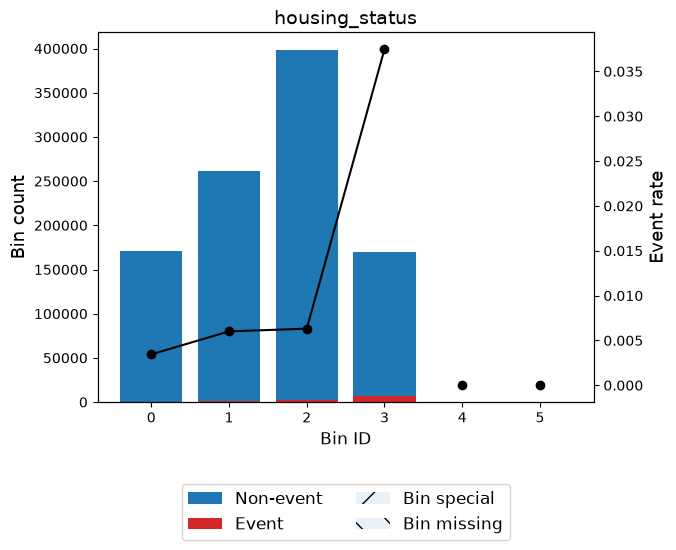

variable source
---------------------------------------------------------
                        Bin    Count  Count (%)  Non-event  Event  Event rate    WoE     IV     JS
0       [INTERNET, TELEAPP]  1000000     1.0000     988971  11029      0.0110 0.0000 0.0000 0.0000
1                   Special        0     0.0000          0      0      0.0000 0.0000 0.0000 0.0000
2                   Missing        0     0.0000          0      0      0.0000 0.0000 0.0000 0.0000
Totals                       1000000     1.0000     988971  11029      0.0110        0.0000 0.0000


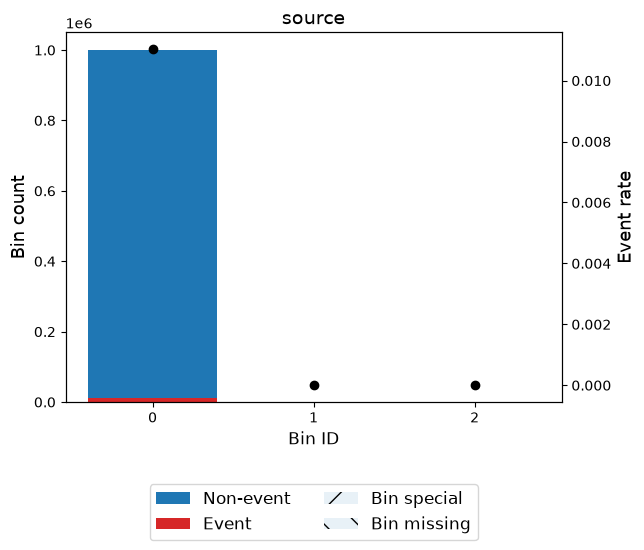

variable device_os
---------------------------------------------------------
                     Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0                [linux]   332712     0.3327     330997   1715      0.0052  0.7666 0.1374 0.0168
1                [other]   342728     0.3427     340754   1974      0.0058  0.6550 0.1084 0.0133
2       [x11, macintosh]    61054     0.0611      60221    833      0.0136 -0.2154 0.0032 0.0004
3              [windows]   263506     0.2635     256999   6507      0.0247 -0.8199 0.2707 0.0329
4                Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
5                Missing        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0000
Totals                    1000000     1.0000     988971  11029      0.0110         0.5196 0.0634


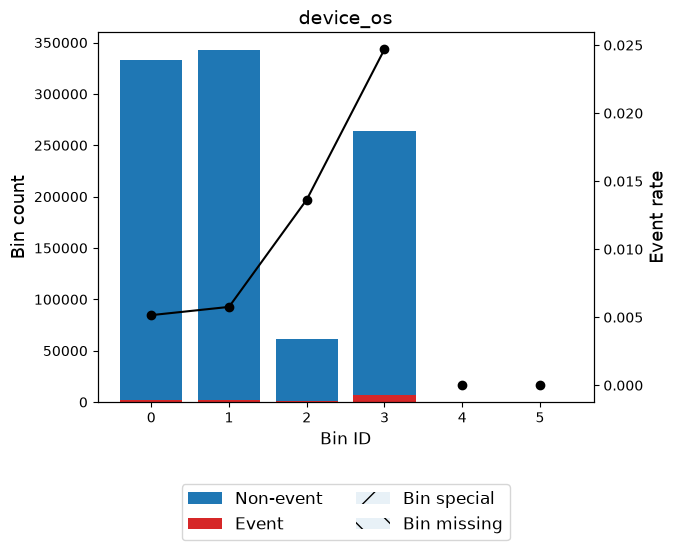

variable period
---------------------------------------------------------
                 Bin    Count  Count (%)  Non-event  Event  Event rate     WoE     IV     JS
0       [2024-03-01]   136979     0.1370     135781   1198      0.0087  0.2343 0.0067 0.0008
1       [2024-04-01]   150936     0.1509     149544   1392      0.0092  0.1807 0.0045 0.0006
2       [2024-02-01]   127620     0.1276     126422   1198      0.0094  0.1628 0.0031 0.0004
3       [2024-01-01]   132440     0.1324     130940   1500      0.0113 -0.0269 0.0001 0.0000
4       [2024-05-01]   127691     0.1277     126239   1452      0.0114 -0.0309 0.0001 0.0000
5       [2024-06-01]   119323     0.1193     117912   1411      0.0118 -0.0705 0.0006 0.0001
6       [2024-07-01]   108168     0.1082     106718   1450      0.0134 -0.1975 0.0047 0.0006
7       [2024-08-01]    96843     0.0968      95415   1428      0.0147 -0.2942 0.0097 0.0012
8            Special        0     0.0000          0      0      0.0000  0.0000 0.0000 0.0

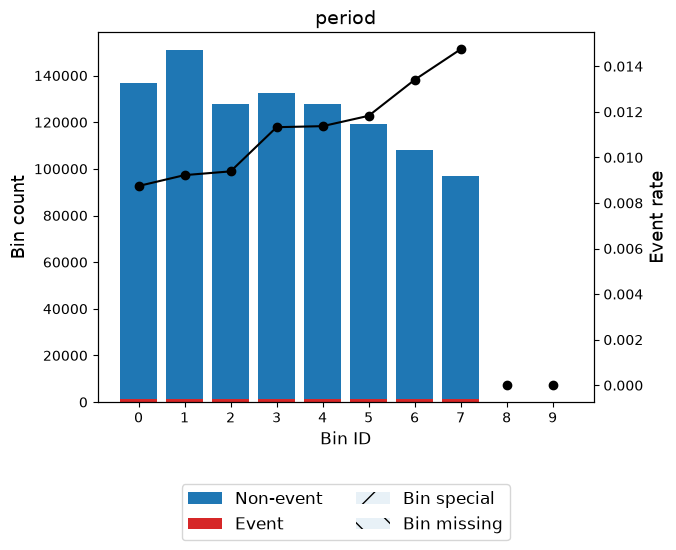

In [26]:
# Ejecutar el análisis con el umbral de 0.03
df_result_cat = plot_analisis(df_cat, 'categorical', columnas_categoricas, 'target', 0.05)

In [27]:
# Ver el DataFrame completo
print(df_result_cat)

               index        IV
0     housing_status  0.823668
1          device_os  0.519638
2       payment_type  0.156460
3  employment_status  0.150415


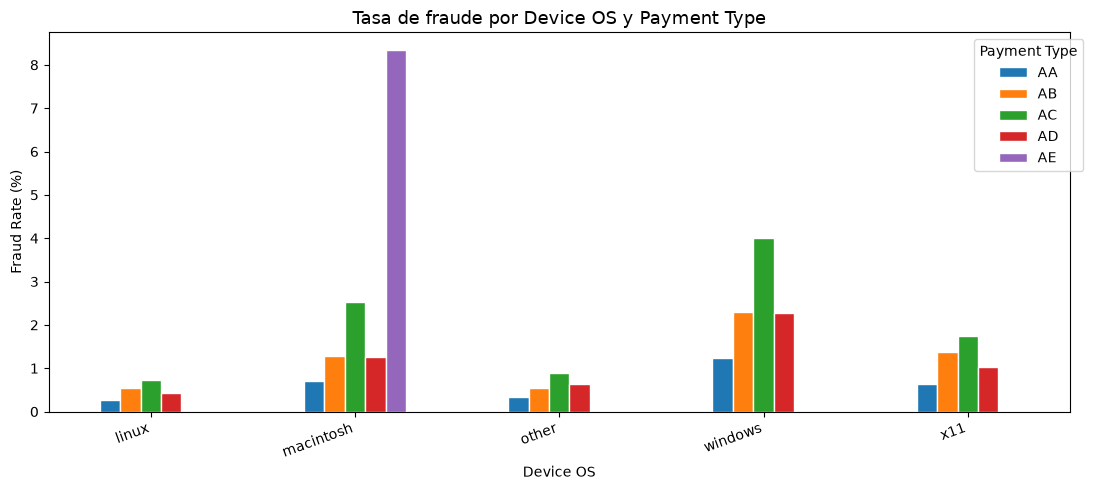

In [28]:
ct = (
    df_data
    .groupby(["device_os", "payment_type"])["target"]
    .mean()
    .mul(100)
    .unstack()
)

ct.plot(
    kind="bar",
    figsize=(11,5),
    edgecolor="white"
)

plt.title("Tasa de fraude por Device OS y Payment Type", fontsize=13)
plt.xlabel("Device OS")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Payment Type", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

# Análisis de correlaciones

## Pearson

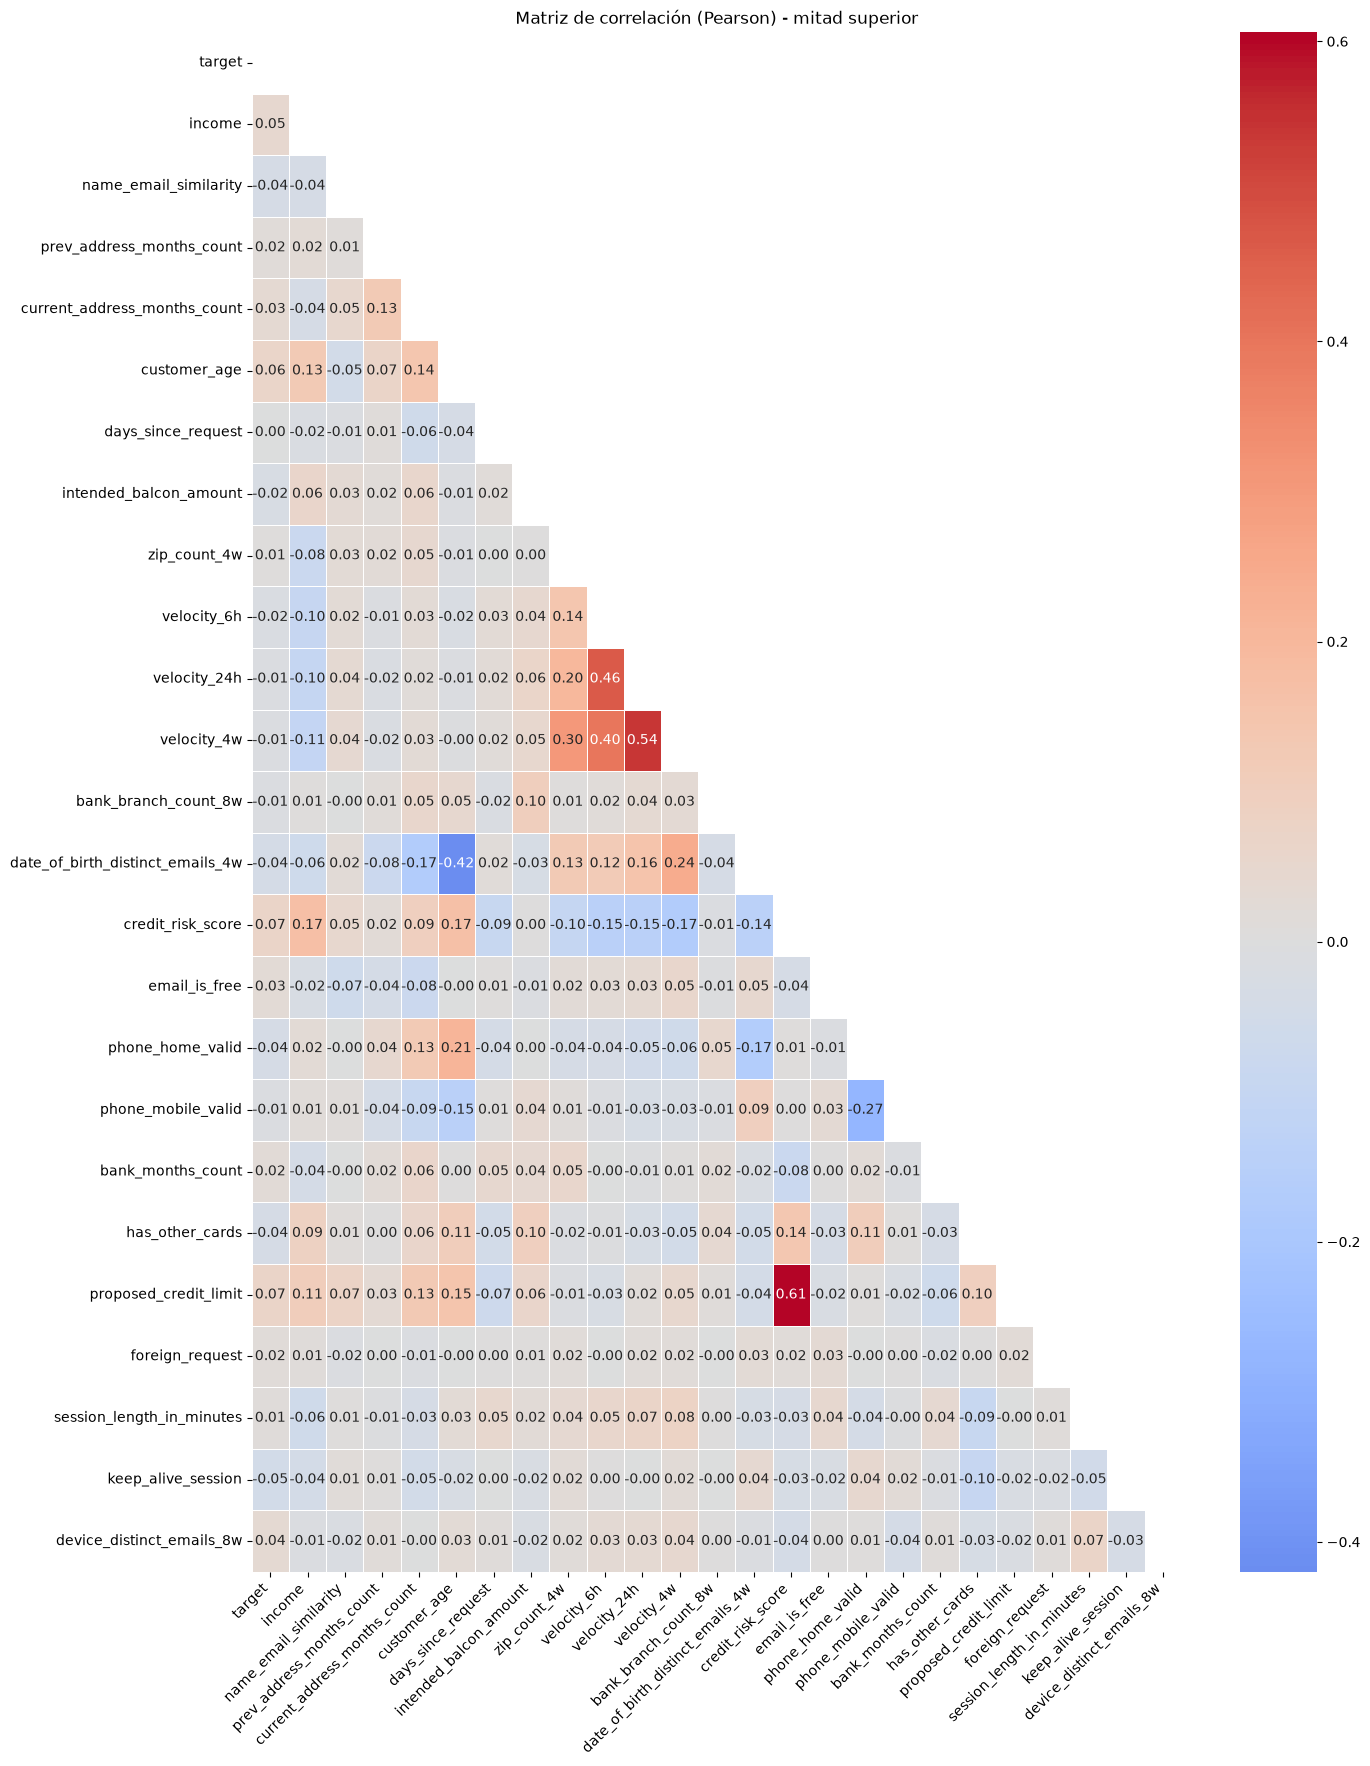

In [29]:
# Matriz de correlación de Pearson con el target incluido y mostrando solo la mitad superior
numeric_df = df_data.select_dtypes(include=['number'])

if 'target' in numeric_df.columns:
    corr_matrix = numeric_df.corr(method='pearson')
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
    corr_matrix = corr_matrix.where(~np.eye(len(corr_matrix), dtype=bool))

    plt.figure(figsize=(15, 20))
    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        cmap='coolwarm',
        center=0,
        fmt='.2f',
        linewidths=0.5
    )
    plt.title('Matriz de correlación (Pearson) - mitad superior')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.show()
else:
    print('No se encontró la columna target en el DataFrame.')

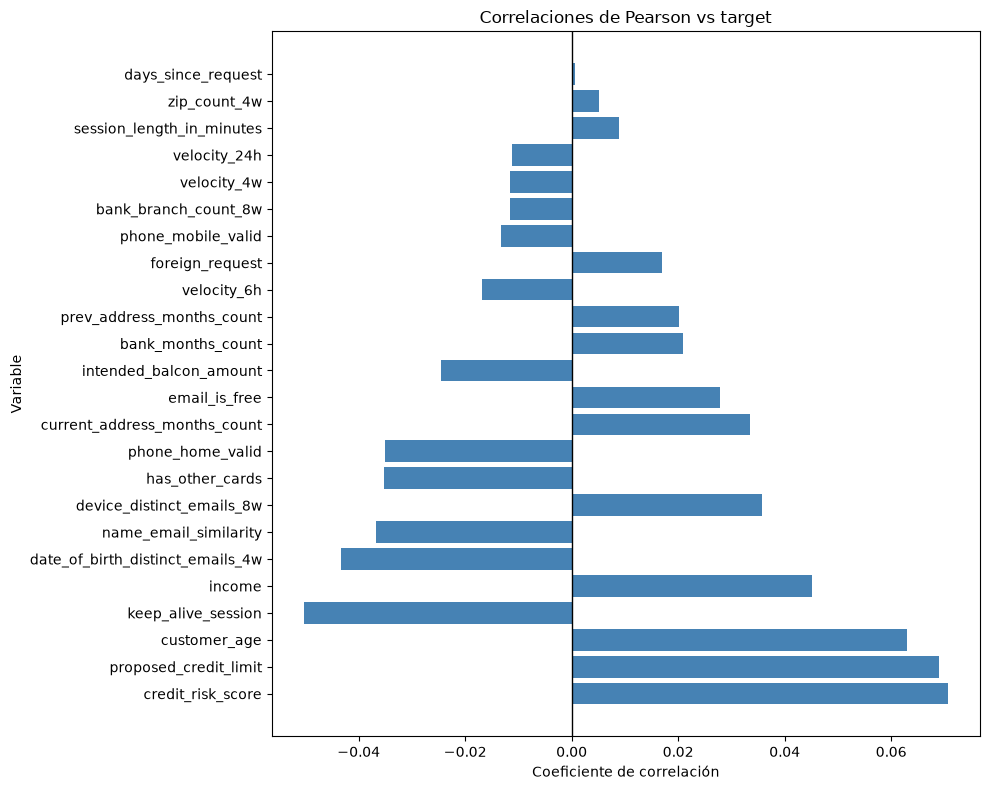

In [30]:
# Correlaciones de Pearson entre variables numéricas y el target
numeric_df = df_data.select_dtypes(include=['number'])

if 'target' in numeric_df.columns:
    features = [col for col in numeric_df.columns if col != 'target']
    correlations = pd.DataFrame(
        {'correlacion': [numeric_df[col].corr(numeric_df['target'], method='pearson') for col in features]},
        index=features
    ).sort_values('correlacion', key=lambda x: x.abs(), ascending=False)

    plt.figure(figsize=(10, 8))
    plt.barh(correlations.index, correlations['correlacion'], color='steelblue')
    plt.axvline(0, color='black', linewidth=1)
    plt.title('Correlaciones de Pearson vs target')
    plt.xlabel('Coeficiente de correlación')
    plt.ylabel('Variable')
    plt.tight_layout()
    plt.show()
else:
    print('No se encontró la columna target en el DataFrame.')

### Semaforización

In [31]:
import numpy as np
import pandas as pd
from typing import Optional


# Función para mostrar 3 niveles de correlación
def categorizar_correlaciones(
    corr: pd.DataFrame,
    usar_abs: bool = True,
    imprimir: bool = True,
    top_por_categoria: Optional[int] = None
):

    mat = corr.abs() if usar_abs else corr.copy()

    mask = np.triu(np.ones(mat.shape, dtype=bool), k=1)
    pares = mat.where(mask).stack().reset_index()
    pares.columns = ["var_1", "var_2", "corr"]

    pares["corr_pct"] = pares["corr"] * 100

    bins = [-0.0000001, 10, 60, 100]
    labels = ["Aceptable", "Medio", "Alto"]

    pares["categoria"] = pd.cut(
        pares["corr_pct"],
        bins=bins,
        labels=labels,
        right=True
    )

    pares = pares.sort_values(
        "corr",
        ascending=False
    ).reset_index(drop=True)

    salida = {}

    for cat in ["Alto", "Medio", "Aceptable"]:

        df_cat = pares.loc[
            pares["categoria"] == cat,
            ["var_1", "var_2", "corr", "corr_pct"]
        ].copy()

        df_cat["corr_pct"] = df_cat["corr_pct"].round(2)

        if top_por_categoria is not None:
            df_cat = df_cat.head(top_por_categoria)

        salida[cat] = df_cat

    if imprimir:

        signo = "|corr|" if usar_abs else "corr"

        print(f"\n=== Clasificación por {signo} (pares únicos, sin duplicados) ===")

        for cat in ["Alto", "Medio", "Aceptable"]:

            df_cat = salida[cat]

            print(f"\n--- {cat} ({len(df_cat)} pares) ---")

            if df_cat.empty:
                print("No hay pares en esta categoría.")

            else:

                for _, r in df_cat.iterrows():
                    print(
                        f"{r['var_1']} vs {r['var_2']}: {r['corr_pct']}%"
                    )

    return salida

In [32]:
df_num = df_data.select_dtypes(include=[np.number])
df_corr = df_num.corr(method='pearson')

#salida = categorizar_correlaciones(df_corr, usar_abs=True, imprimir=True, top_por_categoria=5)
salida = categorizar_correlaciones(df_corr, usar_abs=True, imprimir=True)


=== Clasificación por |corr| (pares únicos, sin duplicados) ===

--- Alto (1 pares) ---
credit_risk_score vs proposed_credit_limit: 60.61%

--- Medio (36 pares) ---
velocity_24h vs velocity_4w: 53.91%
velocity_6h vs velocity_24h: 46.4%
customer_age vs date_of_birth_distinct_emails_4w: 42.02%
velocity_6h vs velocity_4w: 40.03%
zip_count_4w vs velocity_4w: 30.3%
phone_home_valid vs phone_mobile_valid: 27.24%
velocity_4w vs date_of_birth_distinct_emails_4w: 24.24%
customer_age vs phone_home_valid: 21.27%
zip_count_4w vs velocity_24h: 20.12%
current_address_months_count vs date_of_birth_distinct_emails_4w: 17.45%
income vs credit_risk_score: 17.14%
velocity_4w vs credit_risk_score: 16.88%
date_of_birth_distinct_emails_4w vs phone_home_valid: 16.66%
customer_age vs credit_risk_score: 16.61%
velocity_24h vs date_of_birth_distinct_emails_4w: 15.54%
customer_age vs proposed_credit_limit: 14.89%
customer_age vs phone_mobile_valid: 14.71%
velocity_24h vs credit_risk_score: 14.68%
velocity_6h vs

In [33]:
from IPython.display import display

for categoria, df in salida.items():
    print(f"\n===== {categoria} ({len(df)} pares) =====")
    display(df)


===== Alto (1 pares) =====


,var_1,var_2,corr,corr_pct
0,credit_risk_score,proposed_credit_limit,0.606141,60.61



===== Medio (36 pares) =====


,var_1,var_2,corr,corr_pct
1,velocity_24h,velocity_4w,0.539115,53.91
2,velocity_6h,velocity_24h,0.464003,46.40
3,customer_age,date_of_birth_distinct_emails_4w,0.420173,42.02
4,velocity_6h,velocity_4w,0.400254,40.03
5,zip_count_4w,velocity_4w,0.302955,30.30
6,phone_home_valid,phone_mobile_valid,0.272392,27.24
7,velocity_4w,date_of_birth_distinct_emails_4w,0.242365,24.24
8,customer_age,phone_home_valid,0.212713,21.27
9,zip_count_4w,velocity_24h,0.201186,20.12
10,current_address_months_count,date_of_birth_distinct_emails_4w,0.174524,17.45



===== Aceptable (263 pares) =====


,var_1,var_2,corr,corr_pct
37,has_other_cards,keep_alive_session,0.098102,9.81
38,intended_balcon_amount,has_other_cards,0.096676,9.67
39,income,velocity_6h,0.096431,9.64
40,has_other_cards,proposed_credit_limit,0.096254,9.63
41,current_address_months_count,credit_risk_score,0.094870,9.49
42,date_of_birth_distinct_emails_4w,phone_mobile_valid,0.093366,9.34
43,has_other_cards,session_length_in_minutes,0.092773,9.28
44,days_since_request,credit_risk_score,0.088141,8.81
45,current_address_months_count,phone_mobile_valid,0.088008,8.80
46,income,has_other_cards,0.086861,8.69


### Multicolinealidad

Pearson r (credit_risk_score, proposed_credit_limit) = 0.606


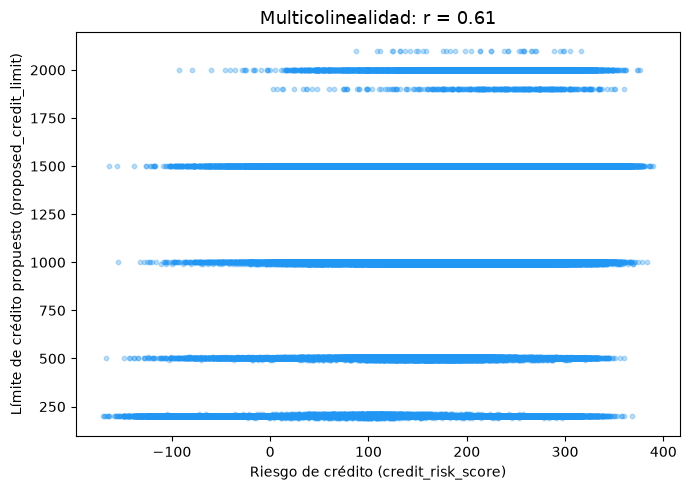

In [34]:
r = df_data["credit_risk_score"].corr(df_data["proposed_credit_limit"])
print(f"Pearson r (credit_risk_score, proposed_credit_limit) = {r:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df_data["credit_risk_score"], df_data["proposed_credit_limit"],
           alpha=0.3, s=10, color="#2196F3")
ax.set_xlabel("Riesgo de crédito (credit_risk_score)")
ax.set_ylabel("Límite de crédito propuesto (proposed_credit_limit)")
ax.set_title(f"Multicolinealidad: r = {r:.2f}", fontsize=13)
plt.tight_layout()
plt.show()

Pearson r (velocity_24h, velocity_4w) = 0.539


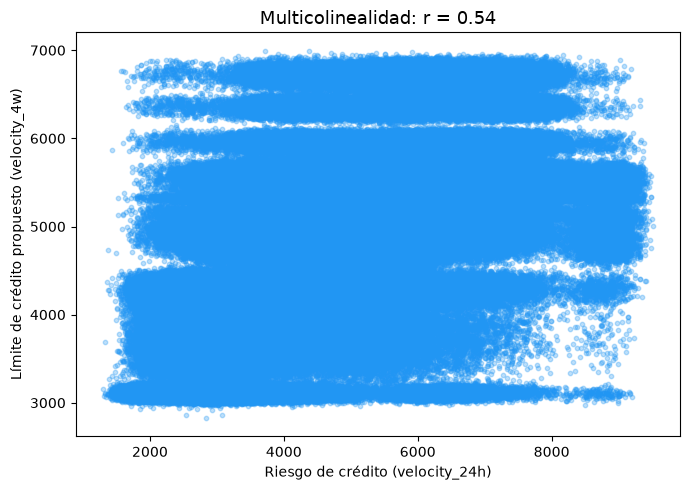

In [35]:
r = df_data["velocity_24h"].corr(df_data["velocity_4w"])
print(f"Pearson r (velocity_24h, velocity_4w) = {r:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df_data["velocity_24h"], df_data["velocity_4w"],
           alpha=0.3, s=10, color="#2196F3")
ax.set_xlabel("Riesgo de crédito (velocity_24h)")
ax.set_ylabel("Límite de crédito propuesto (velocity_4w)")
ax.set_title(f"Multicolinealidad: r = {r:.2f}", fontsize=13)
plt.tight_layout()
plt.show()


# Pairplot de variables seleccionadas

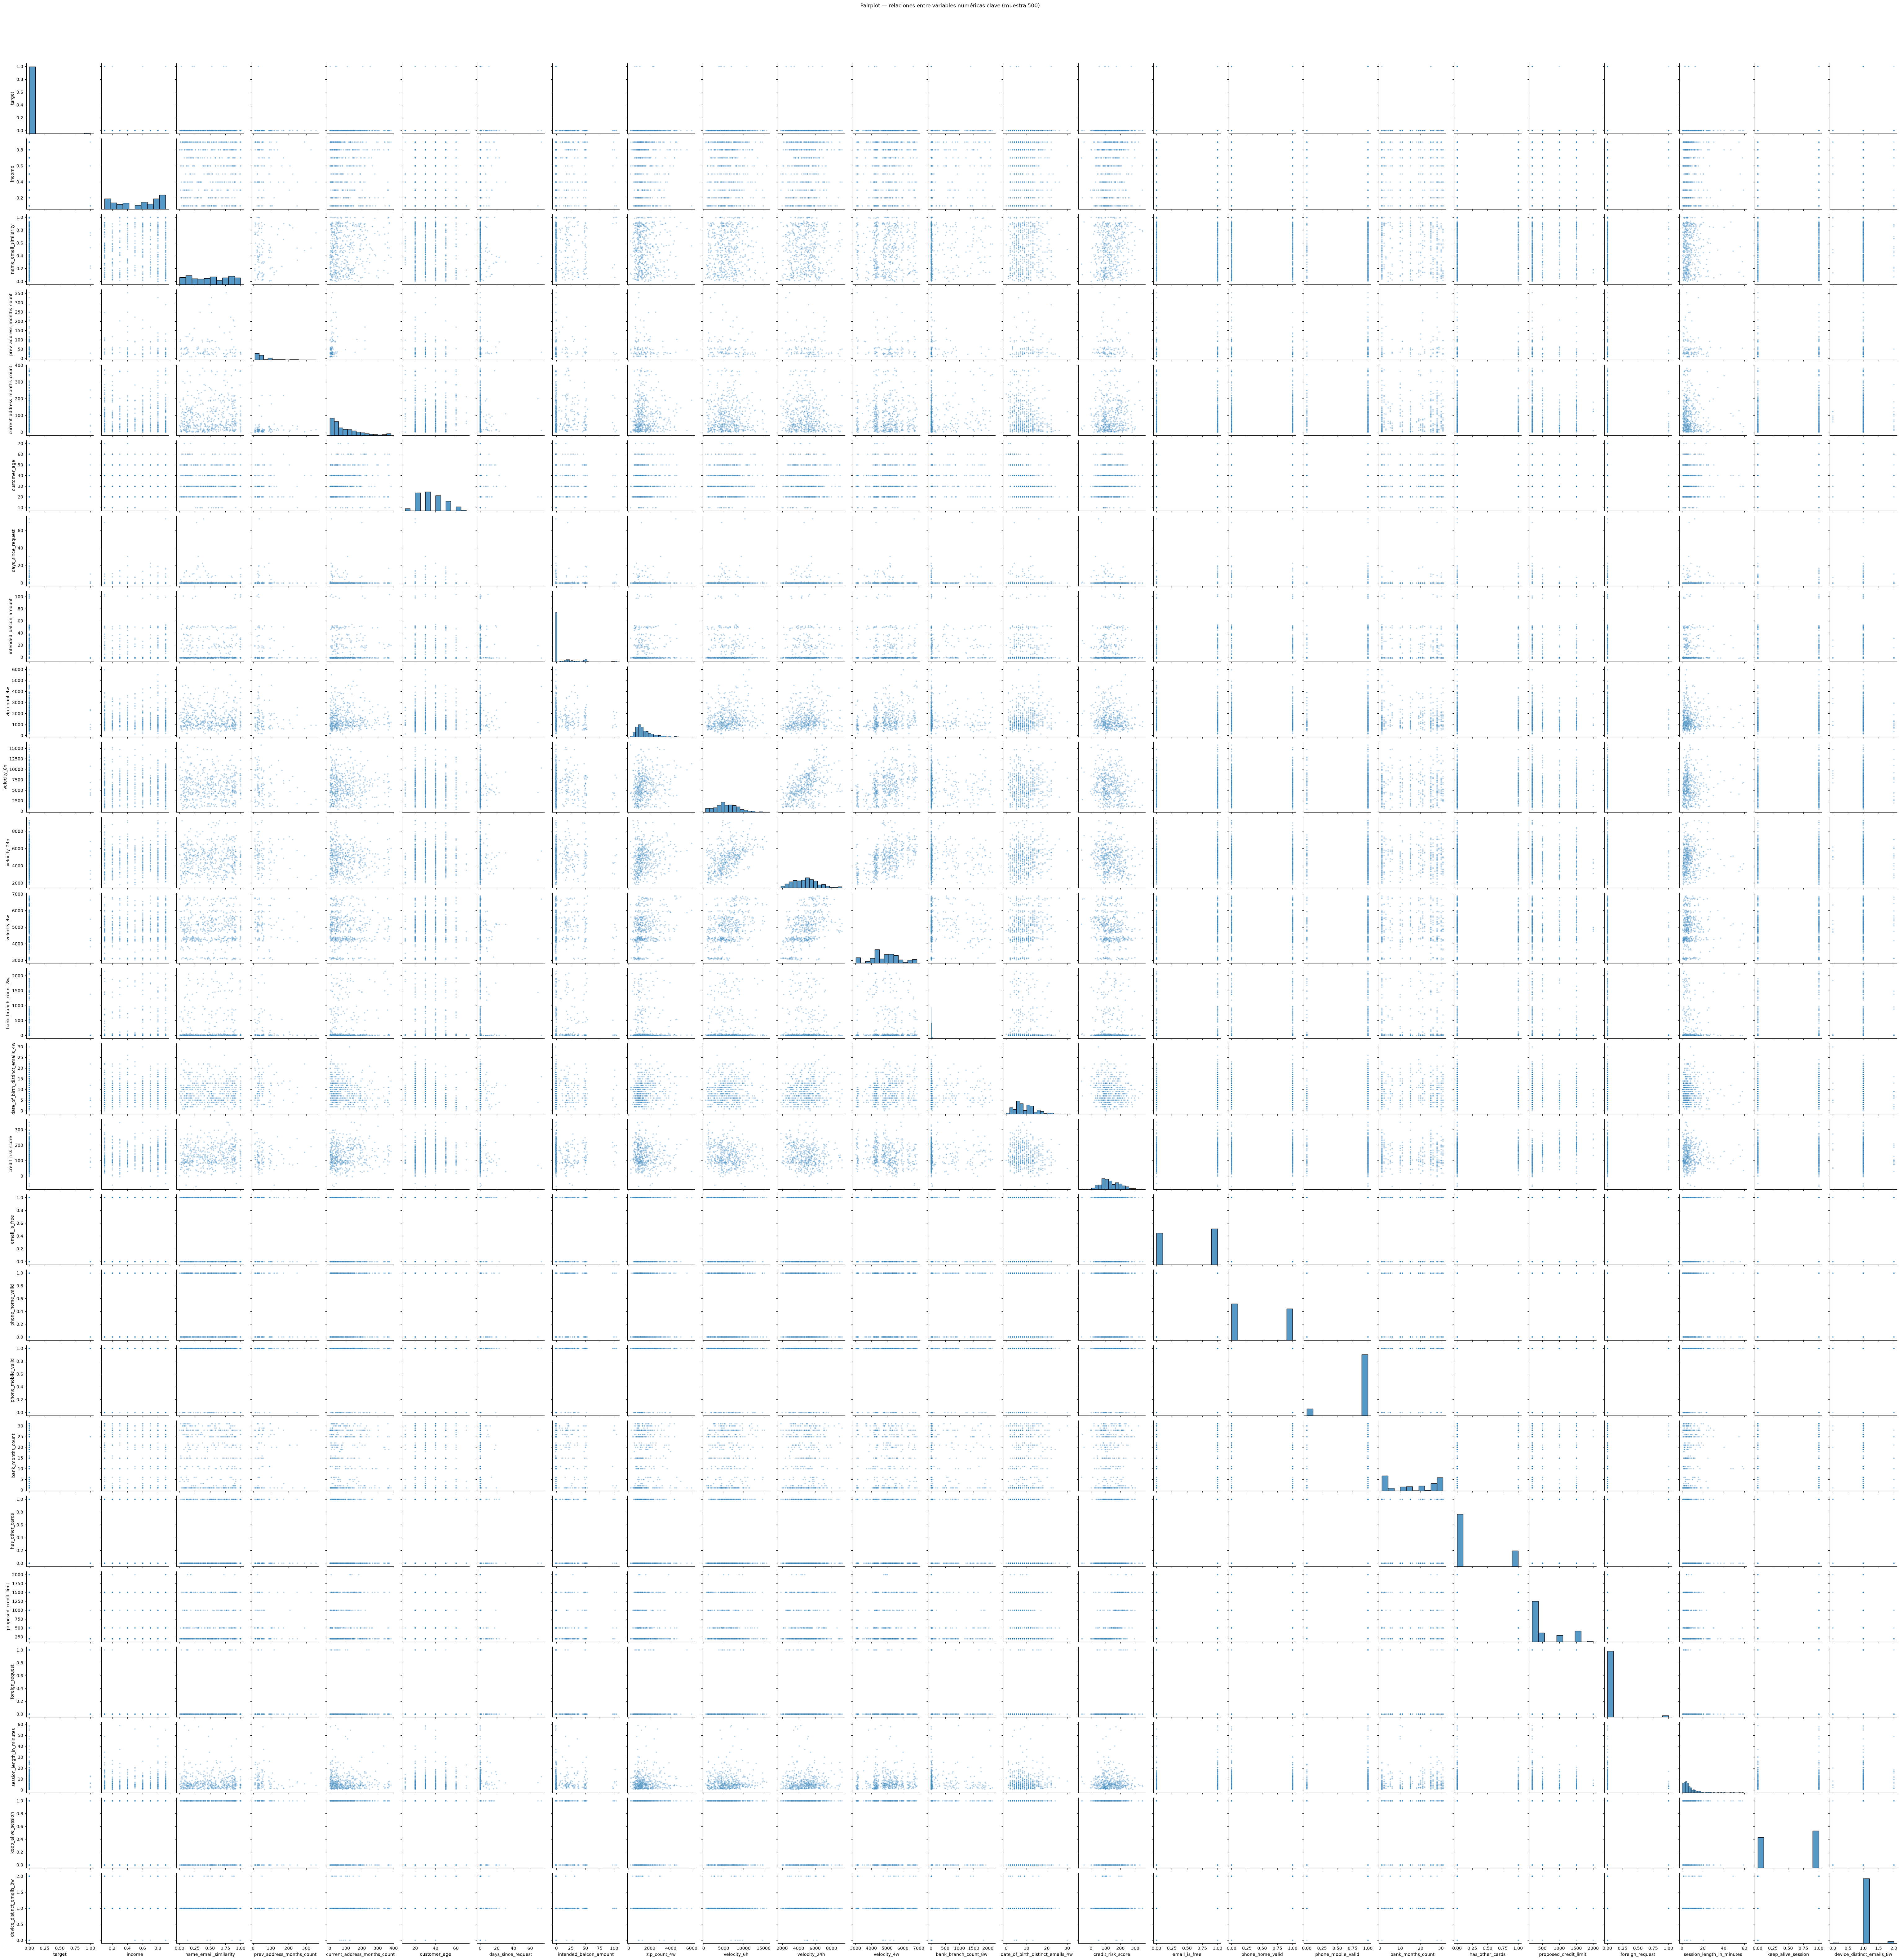

In [36]:
pairplot_cols = df_data.select_dtypes(include=[np.number]).columns.tolist()

g = sns.pairplot(df_data[pairplot_cols].sample(500, random_state=42),
                 diag_kind="hist", plot_kws={"alpha": 0.3, "s": 10})
g.figure.suptitle("Pairplot — relaciones entre variables numéricas clave (muestra 500)", y=1.02)
plt.show()

Coeficiente de asimetría (skewness): 0.30
(> 1.0 indica asimetría derecha moderada-alta)


c:\Users\Renzo\miniconda3\envs\breit-fraud-project1\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\Users\Renzo\miniconda3\envs\breit-fraud-project1\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


ValueError: supplied range of [-inf, 5.966146739123692] is not finite

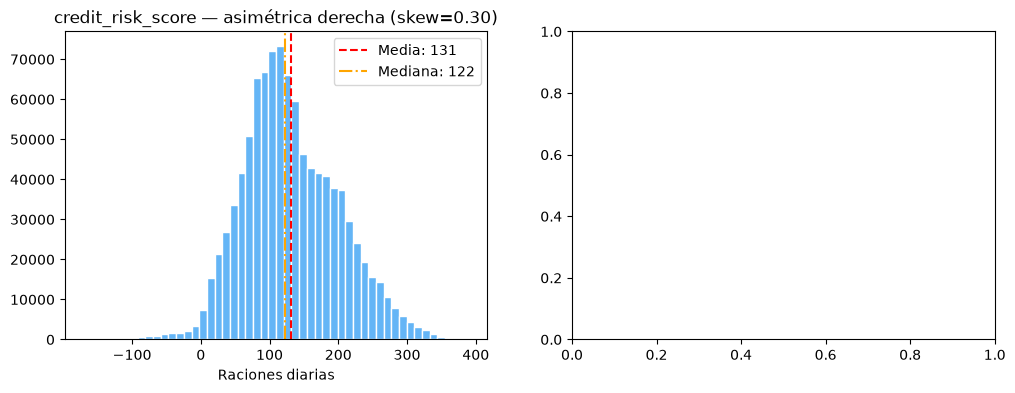

In [37]:
skewness = df_data["credit_risk_score"].skew()
print(f"Coeficiente de asimetría (skewness): {skewness:.2f}")
print("(> 1.0 indica asimetría derecha moderada-alta)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(df_data["credit_risk_score"], bins=50, color="#64B5F6", edgecolor="white")
ax1.axvline(df_data["credit_risk_score"].mean(), color="red", linestyle="--",
            label=f"Media: {df_data['credit_risk_score'].mean():.0f}")
ax1.axvline(df_data["credit_risk_score"].median(), color="orange", linestyle="-.",
            label=f"Mediana: {df_data['credit_risk_score'].median():.0f}")
ax1.set_title(f"credit_risk_score — asimétrica derecha (skew={skewness:.2f})", fontsize=12)
ax1.set_xlabel("Raciones diarias")
ax1.legend()

log_meals = np.log1p(df_data["credit_risk_score"])
ax2.hist(log_meals, bins=50, color="#A5D6A7", edgecolor="white")
ax2.set_title("log1p(credit_risk_score) — distribución más simétrica", fontsize=12)
ax2.set_xlabel("log(1 + raciones diarias)")

plt.tight_layout()
plt.show()


# Split Data

In [38]:
# Quiero dividir df_data en train, test y oot. Train con period 2024-01-01 a 2024-06-30, test con period 2024-07-01 a 2024-07-31 y oot con period 2024-08-01 a 2024-08-31
train_data = df_data[(df_data['period'] >= '2024-01-01') & (df_data['period'] <= '2024-05-31')]
val_data = df_data[(df_data['period'] >= '2024-06-01') & (df_data['period'] <= '2024-06-30')]
test_data = df_data[(df_data['period'] >= '2024-07-01') & (df_data['period'] <= '2024-07-31')]
oot_data = df_data[(df_data['period'] >= '2024-08-01') & (df_data['period'] <= '2024-08-31')]

# Mostrar el tamaño de cada conjunto
print(f"Tamaño del conjunto de entrenamiento (train): {len(train_data)}")
print(f"Tamaño del conjunto de validación (val): {len(val_data)}")
print(f"Tamaño del conjunto de test: {len(test_data)}")
print(f"Tamaño del conjunto de oot: {len(oot_data)}")

Tamaño del conjunto de entrenamiento (train): 675666
Tamaño del conjunto de validación (val): 119323
Tamaño del conjunto de test: 108168
Tamaño del conjunto de oot: 96843


# Fraud Segmentation

Unsupervised clustering is used as an exploratory technique to identify potential behavioral profiles within fraudulent observations. These clusters are not used as the target nor as a replacement for the supervised fraud classification model.

In [39]:
# ============================================================
# 1. Filtrar únicamente observaciones fraudulentas
# ============================================================

fraud_train = train_data[
    train_data["target"] == 1
].copy()

fraud_val = val_data[
    val_data["target"] == 1
].copy()

fraud_test = test_data[
    test_data["target"] == 1
].copy()

fraud_oot = oot_data[
    oot_data["target"] == 1
].copy()


print("Fraudes Train:", len(fraud_train))
print("Fraudes Validation:", len(fraud_val))
print("Fraudes Test:", len(fraud_test))
print("Fraudes OOT:", len(fraud_oot))

Fraudes Train: 6740
Fraudes Validation: 1411
Fraudes Test: 1450
Fraudes OOT: 1428


In [50]:
# ============================================================
# 2. Seleccionar variables numéricas para clustering
# ============================================================

CLUSTER_FEATURES = (
    fraud_train
    .select_dtypes(include=[np.number])
    .columns
    .drop(
        ["target"],
        errors="ignore"
    )
    .tolist()
)

CLUSTER_FEATURES = [
    # Identidad / comportamiento digital
    "name_email_similarity",
    "date_of_birth_distinct_emails_4w",
    "device_distinct_emails_8w",

    # Velocidad / actividad
    "velocity_6h",
    "velocity_24h",
    "velocity_4w",

    # Estabilidad del cliente
    "current_address_months_count",
    "prev_address_months_count",
    "bank_months_count",

    # Perfil crediticio / financiero
    "income",
    "credit_risk_score",
    "proposed_credit_limit",

    # Comportamiento de solicitud
    "days_since_request",
    "session_length_in_minutes",
    "intended_balcon_amount",
]

print(f"Número de variables utilizadas: {len(CLUSTER_FEATURES)}")

Número de variables utilizadas: 15


In [51]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# ============================================================
# 3. Preparar datos de Train
# ============================================================

X_fraud_train = fraud_train[CLUSTER_FEATURES].copy()

# ------------------------------------------------------------
# Imputación
# ------------------------------------------------------------

# La mediana se aprende únicamente con Train
imputer_kmeans = SimpleImputer(
    strategy="median"
)

X_fraud_train_imp = imputer_kmeans.fit_transform(
    X_fraud_train
)

# ------------------------------------------------------------
# Escalamiento
# ------------------------------------------------------------

# StandardScaler también se ajusta únicamente con Train
scaler_kmeans = StandardScaler()

X_fraud_train_scaled = scaler_kmeans.fit_transform(
    X_fraud_train_imp
)

print(
    "Shape Train:",
    X_fraud_train_scaled.shape
)

Shape Train: (6740, 15)


In [52]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ============================================================
# 4. Evaluación del número de clusters
# ============================================================

ks = range(2, 7)

inertias = []
silhouette_scores = []

for k in ks:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        X_fraud_train_scaled
    )

    # Inercia
    inertias.append(
        kmeans.inertia_
    )

    # Silhouette
    silhouette_scores.append(
        silhouette_score(
            X_fraud_train_scaled,
            labels
        )
    )

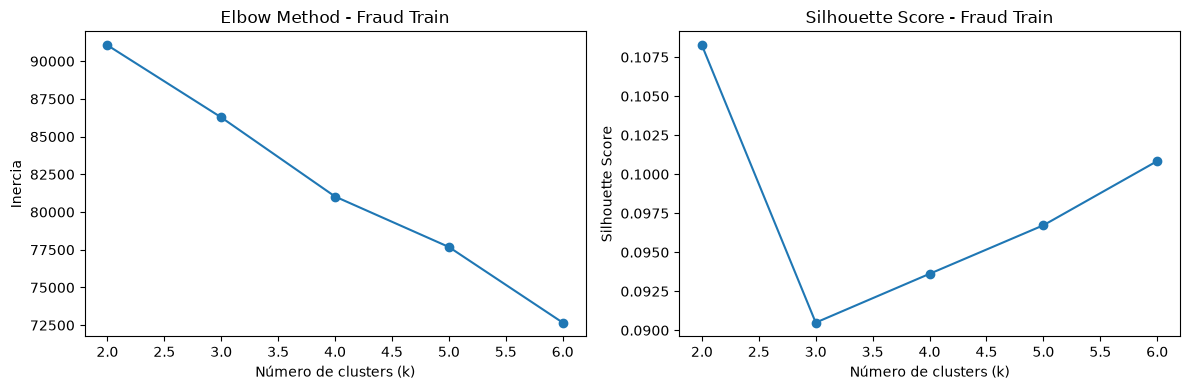

In [53]:
# ============================================================
# 5. Elbow Method + Silhouette Score
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

# ------------------------------------------------------------
# Elbow
# ------------------------------------------------------------

axes[0].plot(
    list(ks),
    inertias,
    marker="o"
)

axes[0].set_title(
    "Elbow Method - Fraud Train"
)

axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inercia")


# ------------------------------------------------------------
# Silhouette
# ------------------------------------------------------------

axes[1].plot(
    list(ks),
    silhouette_scores,
    marker="o"
)

axes[1].set_title(
    "Silhouette Score - Fraud Train"
)

axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [56]:
# ============================================================
# 6. Entrenamiento del KMeans final
# ============================================================

k_final = 2

kmeans_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

fraud_train["cluster"] = kmeans_final.fit_predict(
    X_fraud_train_scaled
)

print("Distribución de clusters - Train:")

print(
    fraud_train["cluster"]
    .value_counts()
    .sort_index()
)

Distribución de clusters - Train:
cluster
0    3343
1    3397
Name: count, dtype: int64


Varianza explicada por PC1: 14.09%
Varianza explicada por PC2: 10.05%
Varianza explicada acumulada: 24.14%


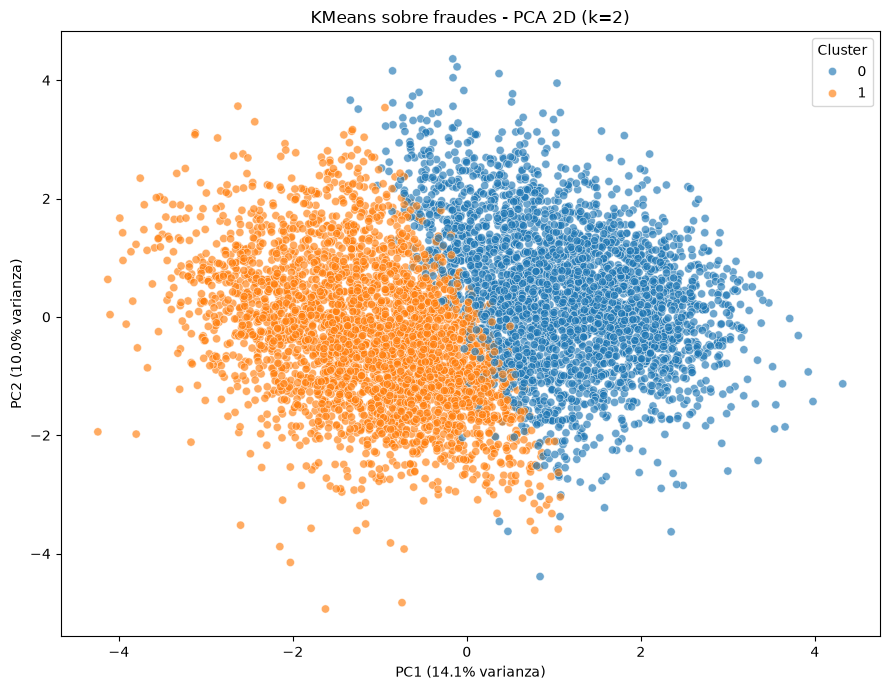

In [57]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 7. PCA para visualizar los clusters en 2 dimensiones
# ============================================================

# PCA se ajusta únicamente sobre el Train escalado.
# No se utiliza para entrenar KMeans en este caso:
# solo sirve para proyectar los datos a 2 dimensiones
# y visualizar la separación entre clusters.

pca = PCA(
    n_components=2,
    random_state=42
)

X_fraud_train_pca = pca.fit_transform(
    X_fraud_train_scaled
)

# Porcentaje de varianza explicada por cada componente
print(
    "Varianza explicada por PC1:",
    f"{pca.explained_variance_ratio_[0]:.2%}"
)

print(
    "Varianza explicada por PC2:",
    f"{pca.explained_variance_ratio_[1]:.2%}"
)

print(
    "Varianza explicada acumulada:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)


# ============================================================
# 8. Visualización PCA de los clusters de Train
# ============================================================

pca_train_df = pd.DataFrame({
    "PC1": X_fraud_train_pca[:, 0],
    "PC2": X_fraud_train_pca[:, 1],
    "cluster": fraud_train["cluster"].values
})

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_train_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    alpha=0.65,
    s=35
)

plt.title(
    f"KMeans sobre fraudes - PCA 2D "
    f"(k={k_final})"
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.1%} varianza)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.1%} varianza)"
)

plt.legend(
    title="Cluster"
)

plt.tight_layout()
plt.show()